# Taller Final de Inteligencia Computacional — Punto 2: Máquinas de Soporte Vectorial (SVM)

**Universidad Pedagógica y Tecnológica de Colombia — Inteligencia Computacional**
**Grupo:** Silva · León · Tobar · Gómez
**Dataset:** *Shoe vs Sandal vs Boot Dataset (15K images)* — Kaggle, `hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images`
**Semilla aleatoria:** `3119` (últimos 4 dígitos del código del estudiante líder)

**Cómo leer este notebook.** Cada paso se presenta con la misma estructura: **qué se hace**, **por qué se decide así (causa)** y **qué impacto tiene**, tanto el esperado como el medido cuando es posible. Cada celda de código comienza con un bloque de comentarios que resume su propósito, y las líneas no evidentes llevan su propia explicación.

| Sección | Contenido |
|---|---|
| 0 | Información del equipo de implementación |
| 1 | Formalización del problema |
| 2 | Carga del dataset y detección de anomalías |
| 3 | Análisis exploratorio de datos (EDA) |
| 4 | Preprocesamiento: decisiones, causas e impacto medido |
| 5 | **Punto 2.1** — las cinco configuraciones (una celda por configuración, para captura de pantalla) |
| 6 | Tabla de experimentos y visualizaciones |
| 7 | **Punto 2.2** — análisis: sobreajuste, impacto de hiperparámetros, complejidad |
| 8 | Limitaciones y recomendaciones |
| 9 | Verificación de reproducibilidad |
| 10 | Uso de los modelos entrenados |
| 11 | Declaración de uso de IA, archivos generados y descarga (Colab) |

### Instrucciones de ejecución

**Origen de los datos.** Por defecto el notebook descarga el dataset desde Kaggle con `kagglehub` (no requiere cuenta, porque el dataset es público). Así, cualquier integrante del grupo obtiene exactamente los mismos datos, en Colab o en su propio equipo. La descarga (~48 MB) se hace una sola vez y queda en caché. Si no hay conexión, se usa una copia local (por ejemplo, la carpeta `Shoe vs Sandal vs Boot Dataset` ubicada junto a la carpeta del notebook).

* **Google Colab:** subir el notebook y ejecutar *Entorno de ejecución → Ejecutar todas*. No se necesita instalar nada. Al final, la sección 11 descarga en un `.zip` los modelos, las figuras y la tabla, porque los archivos que se crean en Colab se borran al cerrar la sesión.
* **VS Code (local):** en la carpeta del notebook, crear el entorno e instalar dependencias:
  ```bash
  python3 -m venv .venv && source .venv/bin/activate
  pip install numpy pandas matplotlib scikit-learn scipy pillow joblib jinja2 kagglehub ipykernel
  ```
  Luego seleccionar `.venv` como kernel (*Select Kernel → Python Environments*).
* Las celdas de la sección 5 se ejecutan **una por una**. Cada salida muestra fecha/hora del sistema, usuario, equipo, métricas y matriz de confusión: es la evidencia que se captura para el informe. En Colab el usuario del sistema siempre es `root`; por eso conviene que la captura incluya la pantalla completa con el reloj del propio computador.
* Tiempo total aproximado: 5 minutos (incluye el experimento de control de la sección 4.3, que puede desactivarse).

### Librerías y parámetros globales

Todos los parámetros que afectan los resultados se concentran en esta celda, para que el experimento sea reproducible y para que cualquier cambio quede a la vista.

| Parámetro | Valor | Causa de la elección | Impacto |
|---|---|---|---|
| `SEED` | 3119 | Lo exige el enunciado (últimos 4 dígitos del código del líder). | Fija la partición 70/30 y cualquier proceso aleatorio: otra persona que ejecute el notebook obtiene exactamente los mismos accuracy y vectores de soporte. |
| `IMG_SIZE` | 32 | Compromiso entre conservar la silueta del calzado y mantener un costo de entrenamiento manejable (sección 4). | Cada imagen pasa de 41 616 valores a 1 024. |
| `VAR_PCA` | 0.80 | Criterio de varianza explicada calculado solo con entrenamiento (sección 4.2). | Define la dimensión del espacio en el que trabaja la SVM (45 componentes). |
| `TEST_SIZE` | 0.30 | Lo exige el enunciado. | 10 500 imágenes de entrenamiento y 4 500 de prueba. |
| `USAR_KAGGLE` | `True` | Que todo el grupo use la misma fuente de datos, en Colab o en local. | Si es `False`, se usa directamente la copia local. |

In [1]:
# =====================================================================================
# QUÉ HACE: importa las librerías y define los parámetros globales del experimento.
# POR QUÉ AQUÍ: si todos los valores que influyen en los resultados están en un solo
# lugar, cualquier cambio queda a la vista y el experimento es reproducible.
# =====================================================================================

# ---- Librerías estándar de Python ----
import os            # rutas de archivos y carpetas
import sys           # detectar si el notebook corre en Google Colab
import time          # cronometrar entrenamientos (time.perf_counter)
import platform      # datos del sistema operativo y del equipo
import getpass       # nombre del usuario del sistema (para las capturas)
import hashlib       # huellas MD5 para detectar imágenes duplicadas
import collections   # Counter y defaultdict para conteos
import json          # guardar metadatos de los modelos
from datetime import datetime   # fecha y hora para las capturas

# ---- Librerías científicas ----
import numpy as np                  # arreglos numéricos: cada imagen será un vector de números
import pandas as pd                 # tablas de resultados
import matplotlib.pyplot as plt     # gráficas
from PIL import Image               # lectura y redimensionamiento de imágenes (Pillow)
import joblib                       # guardar y cargar los modelos entrenados (.joblib)
from scipy.stats import binomtest   # prueba de McNemar para comparar dos modelos (sección 7)

# ---- scikit-learn: preprocesamiento, modelo y métricas ----
import sklearn
from sklearn.model_selection import train_test_split      # partición entrenamiento/prueba
from sklearn.pipeline import Pipeline                     # encadena escalado -> PCA -> SVM en un solo objeto
from sklearn.preprocessing import StandardScaler          # estandariza cada variable (media 0, desviación 1)
from sklearn.decomposition import PCA                     # análisis de componentes principales
from sklearn.svm import SVC                               # máquina de soporte vectorial para clasificación
from sklearn.neighbors import NearestNeighbors            # buscar la imagen de entrenamiento más parecida (sección 4.2 y 7)
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

# ---- Parámetros globales (justificados en la tabla anterior) ----
SEED      = 3119                     # semilla: últimos 4 dígitos del código del líder
IMG_SIZE  = 32                       # lado (en píxeles) al que se reduce cada imagen
VAR_PCA   = 0.80                     # fracción de varianza que debe conservar el PCA
TEST_SIZE = 0.30                     # 30 % de las imágenes para prueba
PREFIJO   = "silva_leon_tobar_gomez" # nomenclatura exigida: apellidos del grupo
CLASES    = ["Boot", "Sandal", "Shoe"]
USAR_KAGGLE      = False              # True: descarga desde Kaggle (igual para todo el grupo)
EJECUTAR_CONTROL = True              # False para omitir el experimento sin PCA (sección 4.3, ~3 min)
EN_COLAB = "google.colab" in sys.modules    # True si el notebook se ejecuta en Google Colab

# ---- Carpetas de salida (se crean si no existen) ----
os.makedirs("modelos", exist_ok=True)   # los 5 modelos entrenados
os.makedirs("figuras", exist_ok=True)   # figuras para el informe

np.random.seed(SEED)                                      # semilla global de NumPy
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})  # tamaño y resolución de las gráficas

def mostrar_tabla(df, formato=None):
    # Muestra un DataFrame sin índice y con formato. Si falta la librería jinja2 (que pandas
    # necesita para .style), muestra la tabla en texto plano en lugar de fallar.
    try:
        estilo = df.style.hide(axis="index")
        return estilo.format(formato) if formato else estilo
    except (AttributeError, ImportError):
        print(df.to_string(index=False))

print("Entorno:", "Google Colab" if EN_COLAB else "local")
print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| Python", platform.python_version())

Entorno: local
scikit-learn 1.9.1 | numpy 2.5.5 | Python 3.14.4


## 0. Información del equipo de implementación

**Qué se hace:** se construye el cuadro exigido en los entregables generales (lenguaje, sistema operativo, procesador, memoria y placa base).
**Por qué se calcula en lugar de escribirse a mano:** los datos se leen del propio sistema (`/proc/cpuinfo`, `/proc/meminfo`, `/sys/class/dmi/id/`), de modo que el cuadro corresponde con certeza al equipo donde se obtuvieron los tiempos de la Tabla 1.
**Impacto:** los tiempos de entrenamiento solo son interpretables junto con el hardware que los produjo; en otro equipo serán distintos, mientras que accuracy y vectores de soporte no cambian. En Colab, el cuadro describe la máquina virtual de Google.

In [2]:
# =====================================================================================
# QUÉ HACE: arma el cuadro de información del equipo leyendo archivos del sistema Linux.
# POR QUÉ: garantiza que el cuadro describe el equipo donde realmente se ejecutó el notebook.
# =====================================================================================

def _leer(ruta):
    # Lee un archivo de texto del sistema y devuelve su contenido.
    # Si no existe (por ejemplo, en Windows o macOS) devuelve None en lugar de fallar.
    try:
        with open(ruta) as f:
            return f.read().strip()
    except Exception:
        return None

def info_equipo():
    # --- Procesador: Linux guarda el nombre comercial en /proc/cpuinfo ("model name") ---
    cpu = platform.processor() or "No disponible"
    cpuinfo = _leer("/proc/cpuinfo")
    if cpuinfo:
        for linea in cpuinfo.splitlines():
            if linea.startswith("model name"):
                cpu = linea.split(":", 1)[1].strip()   # texto después de los dos puntos
                break
    # --- Memoria RAM total: primera línea de /proc/meminfo, expresada en kB ---
    ram = "No disponible"
    meminfo = _leer("/proc/meminfo")
    if meminfo:
        kb = int(meminfo.splitlines()[0].split()[1])
        ram = f"{kb / 1024**2:.1f} GB"                  # kB -> GB
    # --- Placa base: fabricante y modelo que expone el firmware (tabla DMI) ---
    placa = " ".join(x for x in [_leer("/sys/class/dmi/id/board_vendor"),
                                  _leer("/sys/class/dmi/id/board_name")] if x) or "No disponible"
    # --- Sistema operativo: nombre de la distribución (/etc/os-release) + versión del kernel ---
    so = platform.platform()
    os_rel = _leer("/etc/os-release")
    if os_rel:
        for linea in os_rel.splitlines():
            if linea.startswith("PRETTY_NAME="):
                so = linea.split("=", 1)[1].strip('"') + f" (kernel {platform.release()})"
    # --- Se devuelve como tabla de dos columnas ---
    return pd.DataFrame({
        "Elemento": ["Lenguaje de programación", "Librería principal", "Sistema operativo", "Procesador",
                     "Núcleos lógicos", "Memoria RAM", "Placa base", "Usuario", "Equipo (hostname)"],
        "Valor": [f"Python {platform.python_version()}", f"scikit-learn {sklearn.__version__}", so, cpu,
                  os.cpu_count(), ram, placa, getpass.getuser(), platform.node()]})

mostrar_tabla(info_equipo())

Elemento,Valor
Lenguaje de programación,Python 3.14.4
Librería principal,scikit-learn 1.9.1
Sistema operativo,Ubuntu 26.04.1 LTS (kernel 7.0.0-43-generic)
Procesador,Intel(R) Core(TM) Ultra 5 125H
Núcleos lógicos,18
Memoria RAM,30.9 GB
Placa base,GEEKOM NX14C
Usuario,ur92
Equipo (hostname),ms-book


## 1. Formalización del problema

* **Tipo de aprendizaje:** supervisado, clasificación multiclase (3 clases), porque cada imagen viene etiquetada con su tipo de calzado.
* **Variable objetivo:** $y \in \{\text{Boot}, \text{Sandal}, \text{Shoe}\}$.
* **Características:** intensidades de píxel. Las imágenes originales son RGB de 136 × 102 píxeles (41 616 valores); tras el preprocesamiento, cada imagen queda descrita por 45 componentes principales.
* **Modelo:** SVM de margen blando (`sklearn.svm.SVC`). Como la SVM es binaria por naturaleza, scikit-learn resuelve las 3 clases con el esquema *uno contra uno*: entrena un clasificador por cada par de clases (Boot–Sandal, Boot–Shoe, Sandal–Shoe) y asigna la clase que más votos recibe.
* **Métricas:** accuracy de entrenamiento y prueba, precisión, recall y F1 por clase, matriz de confusión, número de vectores de soporte y tiempo de entrenamiento.

**Por qué el problema no es trivial para una SVM.** La SVM no «ve» formas: compara imágenes como vectores, midiendo distancias entre sus píxeles. Dos botas en posiciones ligeramente distintas pueden estar más lejos entre sí que una bota y un zapato alineados. Todas las decisiones de preprocesamiento buscan que esas distancias reflejen lo mejor posible la forma del calzado, y explican varios de los resultados de la sección 7.

## 2. Carga del dataset y detección de anomalías

**Qué se hace:** se obtiene la carpeta que contiene las subcarpetas `Boot`, `Sandal` y `Shoe`.
**Por qué de forma automática:** el mismo notebook debe funcionar sin cambios en Colab y en el equipo de cada integrante. La descarga desde Kaggle garantiza la misma fuente para todos; la copia local es el respaldo cuando no hay conexión.

In [3]:
# =====================================================================================
# QUÉ HACE: devuelve la ruta de la carpeta que contiene Boot/, Sandal/ y Shoe/.
# ORDEN: (1) Kaggle con kagglehub, (2) copias locales conocidas si no hay conexión.
# =====================================================================================

def tiene_clases(ruta):
    # True si la carpeta contiene las tres subcarpetas de clases
    return all(os.path.isdir(os.path.join(ruta, k)) for k in CLASES)

def buscar_clases(base):
    # La descarga de Kaggle puede venir anidada en subcarpetas: os.walk recorre todo el
    # árbol hasta encontrar la carpeta que contiene las tres clases.
    for raiz, dirs, _ in os.walk(base):
        if all(k in dirs for k in CLASES):
            return raiz
    return None

def localizar_dataset():
    if USAR_KAGGLE:
        try:
            try:
                import kagglehub
            except ImportError:
                # Si kagglehub no está instalado, se instala en el entorno actual
                import subprocess
                subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
                import kagglehub
            # Descarga (o reutiliza la caché) y devuelve la carpeta donde quedó el dataset
            base = kagglehub.dataset_download("hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images")
            ruta = buscar_clases(base)
            if ruta:
                return ruta, "Kaggle (kagglehub)"
        except Exception as e:
            print("No fue posible descargar desde Kaggle:", type(e).__name__, "-> se busca una copia local")
    # Respaldo: copias locales (carpeta hermana del notebook, carpeta actual o ruta del líder)
    candidatos = ["../Shoe vs Sandal vs Boot Dataset", "Shoe vs Sandal vs Boot Dataset", "data",
                  os.path.expanduser("~/Documentos/InteligenciaComputacional/Shoe vs Sandal vs Boot Dataset")]
    for c in candidatos:
        if tiene_clases(c):
            return c, "copia local"
    raise FileNotFoundError("No se encontró el dataset: revise la conexión o la ruta de la copia local")

DATA_DIR, ORIGEN = localizar_dataset()
print("Dataset en:", DATA_DIR, "| origen:", ORIGEN)

Dataset en: ../Shoe vs Sandal vs Boot Dataset | origen: copia local


**Qué se hace:** se leen las 15 000 imágenes una sola vez y, en la misma pasada, se registra todo lo necesario para el EDA.

| Qué se registra | Por qué | Impacto si se omitiera |
|---|---|---|
| Tamaño y modo de color de cada imagen | La SVM exige vectores de igual longitud; una imagen de otro tamaño rompería la matriz `X`. | Error en el entrenamiento o píxeles desalineados entre imágenes. |
| Huella MD5 de cada archivo | Detecta imágenes repetidas. Una imagen duplicada que cae en entrenamiento y en prueba infla el accuracy de prueba, porque el modelo «ya la vio». | Fuga de información no detectada. |
| Media y desviación RGB | Describe el dataset (también se reutiliza en el punto 4 del taller). | — |
| Versión gris 32 × 32 normalizada a [0, 1] | Es la representación que recibe el modelo (causas en la sección 4). | — |

In [4]:
# =====================================================================================
# QUÉ HACE: lee las 15 000 imágenes, construye la matriz X (una fila por imagen) y el
# vector y (una etiqueta por imagen), y registra tamaños, colores y duplicados.
# =====================================================================================

X_list, y_list, rutas = [], [], []        # vectores de píxeles, etiquetas y rutas de cada imagen
tamanos, modos = collections.Counter(), collections.Counter()   # conteo de tamaños y modos de color
hashes = collections.defaultdict(list)    # huella MD5 -> lista de archivos con esa huella
suma_rgb = np.zeros(3)                    # suma de valores por canal (para la media)
suma2_rgb = np.zeros(3)                   # suma de cuadrados por canal (para la desviación)
n_pix = 0                                 # número total de píxeles leídos

t0 = time.perf_counter()
for clase in CLASES:
    carpeta = os.path.join(DATA_DIR, clase)
    for f in sorted(os.listdir(carpeta)):          # sorted: el orden de lectura es siempre el mismo
        ruta = os.path.join(carpeta, f)
        # Huella MD5 del archivo: dos archivos con la misma huella son byte a byte idénticos
        with open(ruta, "rb") as fh:
            hashes[hashlib.md5(fh.read()).hexdigest()].append(f"{clase}/{f}")
        im = Image.open(ruta)
        tamanos[im.size] += 1                       # (ancho, alto)
        modos[im.mode] += 1                         # "RGB", "L", etc.
        # Estadísticas RGB: se acumulan sumas para calcular media y desviación al final
        rgb = np.asarray(im.convert("RGB"), dtype=np.float64) / 255.0   # alto x ancho x 3, en [0, 1]
        suma_rgb += rgb.sum(axis=(0, 1))
        suma2_rgb += (rgb ** 2).sum(axis=(0, 1))
        n_pix += rgb.shape[0] * rgb.shape[1]
        # Representación que recibe el modelo:
        #   convert("L")  -> escala de grises: L = 0.299 R + 0.587 G + 0.114 B
        #   resize(32,32) -> cada píxel nuevo es un promedio ponderado (filtro bicúbico) de una zona de ~4 x 3 píxeles
        #   / 255         -> valores en [0, 1]
        #   ravel()       -> la matriz 32 x 32 se aplana en un vector de 1 024 números (fila tras fila)
        gris = im.convert("L").resize((IMG_SIZE, IMG_SIZE))
        X_list.append(np.asarray(gris, dtype=np.float32).ravel() / 255.0)
        y_list.append(clase)
        rutas.append(ruta)

X = np.stack(X_list)            # matriz 15 000 x 1 024
y = np.array(y_list)            # vector de 15 000 etiquetas
media_rgb = suma_rgb / n_pix
std_rgb = np.sqrt(suma2_rgb / n_pix - media_rgb ** 2)    # Var = E[x²] - (E[x])²
duplicados = [v for v in hashes.values() if len(v) > 1]  # huellas que aparecen más de una vez

print(f"Imágenes leídas: {len(y)}  ({time.perf_counter() - t0:.1f} s)")
print("Matriz de características X:", X.shape, "| etiquetas y:", y.shape)
print("Tamaños (ancho, alto):", dict(tamanos))
print("Modos de color:", dict(modos))
print("Media RGB:", np.round(media_rgb, 4), "| Desv. estándar RGB:", np.round(std_rgb, 4))
print(f"Archivos duplicados exactos (MD5): {len(duplicados)} grupos")
for g in duplicados:
    print("   ", g)

Imágenes leídas: 15000  (12.9 s)
Matriz de características X: (15000, 1024) | etiquetas y: (15000,)
Tamaños (ancho, alto): {(136, 102): 14998, (135, 102): 2}
Modos de color: {'RGB': 15000}
Media RGB: [0.8078 0.7795 0.7689] | Desv. estándar RGB: [0.3042 0.3255 0.3332]
Archivos duplicados exactos (MD5): 2 grupos
    ['Boot/boot (1493).jpg', 'Boot/boot (383).jpg']
    ['Boot/boot (1494).jpg', 'Boot/boot (384).jpg']


**Anomalías encontradas y decisión tomada**

* **Dos imágenes de 135 × 102 píxeles** (el resto mide 136 × 102). *Decisión:* conservarlas. *Causa:* la diferencia es de una columna y el redimensionamiento a 32 × 32 las homogeniza. *Impacto:* ninguno sobre el modelo.
* **Dos pares de archivos idénticos en *Boot*** (`boot (383)` = `boot (1493)` y `boot (384)` = `boot (1494)`). *Decisión:* conservarlos y declararlos. *Causa:* representan 4 de 15 000 archivos (0.03 %). *Impacto posible:* si un par queda dividido entre entrenamiento y prueba, el modelo acierta esa imagen de prueba «de memoria»; en el peor caso son 2 imágenes de 4 500 (0.04 p.p.), muy por debajo de cualquier diferencia que se analiza en la sección 7.

## 3. Análisis exploratorio de datos (EDA)

**Distribución de clases.** *Por qué se revisa:* si una clase dominara, un modelo que siempre la predice tendría un accuracy alto sin aprender nada, y el accuracy dejaría de ser una métrica confiable.

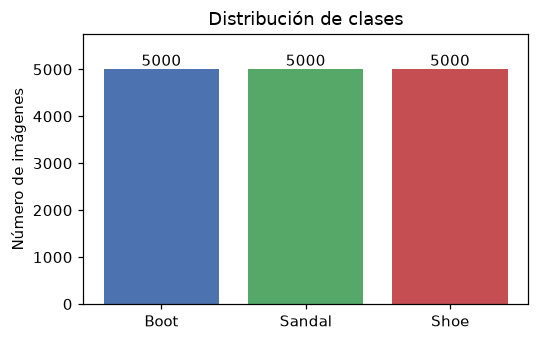

          Boot  Sandal  Shoe
imágenes  5000    5000  5000
Ratio de desbalance (mayor/menor): 1.00


In [5]:
# =====================================================================================
# QUÉ HACE: cuenta las imágenes de cada clase, las grafica y calcula el ratio de desbalance.
# =====================================================================================
conteo = pd.Series(y).value_counts().reindex(CLASES)     # número de imágenes por clase, en orden fijo
fig, ax = plt.subplots(figsize=(5, 3.2))
barras = ax.bar(conteo.index, conteo.values, color=["#4C72B0", "#55A868", "#C44E52"])
ax.bar_label(barras)                                      # escribe el número encima de cada barra
ax.set_ylabel("Número de imágenes"); ax.set_title("Distribución de clases")
ax.set_ylim(0, conteo.max() * 1.15)
plt.tight_layout(); plt.savefig("figuras/eda_distribucion_clases.png"); plt.show()
print(conteo.to_frame("imágenes").T)
print(f"Ratio de desbalance (mayor/menor): {conteo.max() / conteo.min():.2f}")   # > 1.5 indicaría desbalance

**Ejemplos por clase.** *Por qué se revisa:* permite verificar visualmente que las etiquetas son coherentes y observar qué rasgos distinguen a cada clase antes de modelar.

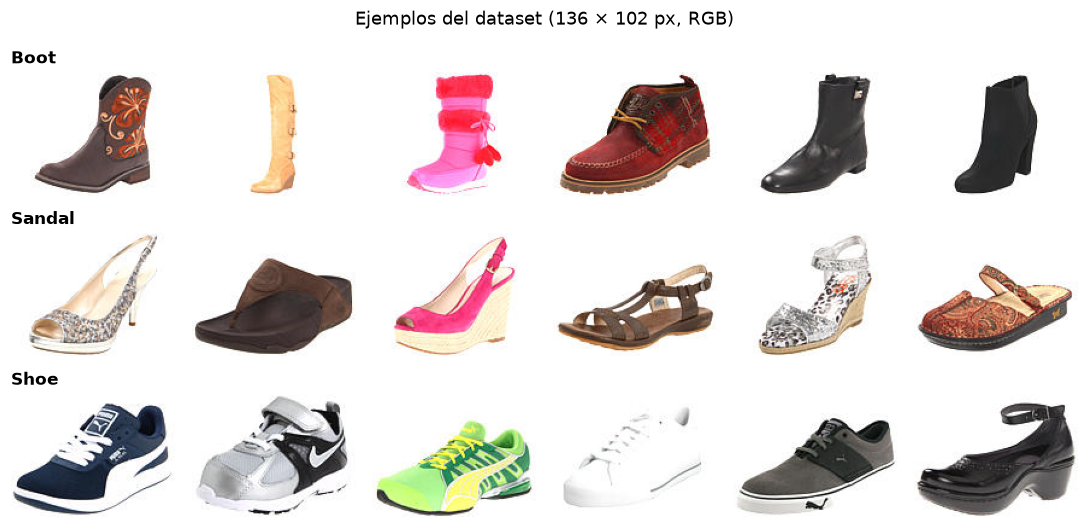

In [6]:
# =====================================================================================
# QUÉ HACE: muestra 6 imágenes aleatorias de cada clase, en su tamaño y color originales.
# =====================================================================================
rng = np.random.default_rng(SEED)        # generador con semilla: siempre muestra las mismas imágenes
fig, axes = plt.subplots(3, 6, figsize=(10, 5))
for i, clase in enumerate(CLASES):
    idx = rng.choice(np.where(y == clase)[0], 6, replace=False)   # 6 índices distintos de esa clase
    for j, k in enumerate(idx):
        axes[i, j].imshow(Image.open(rutas[k]).convert("RGB"))
        axes[i, j].axis("off")
    axes[i, 0].set_title(clase, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Ejemplos del dataset (136 × 102 px, RGB)"); plt.tight_layout()
plt.savefig("figuras/eda_ejemplos.png"); plt.show()

**Imagen promedio y desviación por clase.** *Por qué se revisa:* muestra la información que realmente recibe el modelo (gris, 32 × 32) y anticipa qué clases serán difíciles de separar: si dos imágenes promedio se parecen, sus ejemplos estarán cerca en el espacio de píxeles.

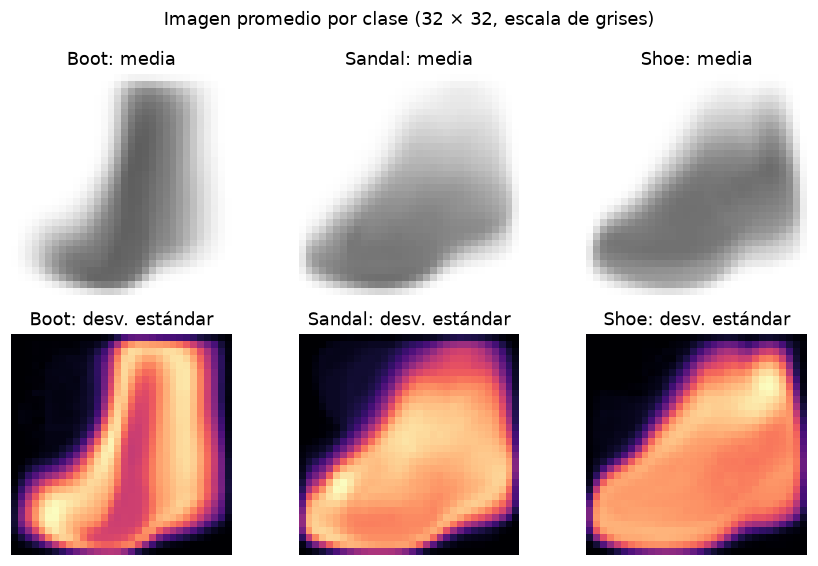

Estadísticas de intensidad (gris, escala [0,1]) por clase:
         media  desv. estándar  mínimo  máximo
Boot    0.7883          0.2994  0.0078     1.0
Sandal  0.8060          0.2895  0.0000     1.0
Shoe    0.7630          0.3184  0.0000     1.0


In [7]:
# =====================================================================================
# QUÉ HACE: calcula, píxel a píxel, la imagen promedio y la desviación estándar de cada clase.
# LECTURA: la media muestra la forma típica; la desviación muestra dónde varían más las imágenes.
# =====================================================================================
fig, axes = plt.subplots(2, 3, figsize=(8, 5.2))
for j, clase in enumerate(CLASES):
    Xc = X[y == clase]                                       # solo las imágenes de esa clase
    axes[0, j].imshow(Xc.mean(0).reshape(IMG_SIZE, IMG_SIZE), cmap="gray", vmin=0, vmax=1)   # vector -> 32x32
    axes[0, j].set_title(f"{clase}: media"); axes[0, j].axis("off")
    axes[1, j].imshow(Xc.std(0).reshape(IMG_SIZE, IMG_SIZE), cmap="magma")
    axes[1, j].set_title(f"{clase}: desv. estándar"); axes[1, j].axis("off")
plt.suptitle("Imagen promedio por clase (32 × 32, escala de grises)"); plt.tight_layout()
plt.savefig("figuras/eda_media_por_clase.png"); plt.show()

# Estadísticas de intensidad de todos los píxeles de cada clase
stats = pd.DataFrame({c: pd.Series(X[y == c].ravel()).describe()[["mean", "std", "min", "max"]] for c in CLASES}).T
stats.columns = ["media", "desv. estándar", "mínimo", "máximo"]
print("Estadísticas de intensidad (gris, escala [0,1]) por clase:")
print(stats.round(4))

### Conclusiones del EDA y su impacto en el diseño

* **Clases perfectamente balanceadas** (5 000 por clase, ratio 1.00 < 1.5). *Impacto:* el accuracy es una métrica representativa y no se necesita ponderar clases (`class_weight='balanced'`). Un modelo que adivine al azar obtiene 33.3 %, valor de referencia que se usa en la sección 7.
* **Fondo blanco uniforme** (medias RGB ≈ 0.81, 0.78, 0.77). *Impacto:* la información útil está en la silueta del calzado, no en el fondo ni en el color, lo que justifica trabajar en escala de grises (sección 4).
* **La bota es visualmente distinta; sandalia y zapato se parecen.** La bota presenta una caña vertical alta, mientras que sandalia y zapato comparten un perfil bajo similar; la sandalia es en promedio más clara (0.8060 frente a 0.7630) porque sus aberturas dejan ver el fondo. *Impacto esperado:* la mayoría de los errores ocurrirá entre *Sandal* y *Shoe*, y *Boot* será la clase más fácil. La sección 7 confirma ambas predicciones.

## 4. Preprocesamiento: decisiones, causas e impacto

Cada decisión se tomó **antes** de mirar el conjunto de prueba, para no adaptar el modelo a los datos con los que se le evalúa.

| # | Decisión | Causa (por qué) | Impacto esperado | Impacto medido |
|---|---|---|---|---|
| D1 | Convertir a escala de grises | El fondo es blanco y las clases se distinguen por la silueta, no por el color (EDA). | Divide por 3 el número de variables sin perder la forma. | Imágenes de 41 616 → 13 872 valores (antes de redimensionar). |
| D2 | Redimensionar a 32 × 32 (1 024 variables) | El costo de `SVC` crece aproximadamente con el cuadrado del número de muestras multiplicado por la dimensión; con 10 500 muestras de entrenamiento y 13 872 variables, el entrenamiento sería de muchos minutos por configuración. | Pierde detalle fino (cordones, correas), pero conserva la silueta, visible en la imagen promedio. | Ver sección 4.3 (tiempos sin PCA). |
| D3 | `StandardScaler` dentro del `Pipeline` | La SVM decide con distancias; una variable con escala mayor dominaría la distancia. Al estar dentro del pipeline, la media y la desviación se calculan **solo con entrenamiento**. | Evita la fuga de información (*data leakage*): el conjunto de prueba se trata como datos nunca vistos. | — |
| D4 | PCA que conserva el 80 % de la varianza, con blanqueo | (a) Los píxeles vecinos están muy correlacionados: 1 024 variables contienen mucha información repetida. (b) **Los valores de γ que fija el enunciado (0.1 y 1.0) solo son razonables en un espacio de pocas dimensiones**: en el kernel RBF la distancia entre imágenes crece con el número de variables, y con 1 024 variables cualquier imagen nueva queda tan «lejos» de todas las de entrenamiento que el kernel vale prácticamente cero (medido en la sección 4.2). (c) El blanqueo divide cada componente entre su desviación estándar, de modo que todas pesan igual en la distancia (sin él, la primera componente tendría 63 veces más varianza que la última). | Menos ruido, entrenamiento mucho más rápido y valores de γ que producen comportamientos distintos y comparables. Costo: se descarta el 20 % de la varianza. | Sección 4.3: sin PCA, la configuración #2 cae a un accuracy de prueba cercano al azar y el entrenamiento es mucho más lento. |
| D5 | Partición estratificada 70/30 con semilla 3119 | Lo exige el enunciado; la estratificación conserva 1/3 de cada clase en ambos conjuntos. | El accuracy de prueba no se ve sesgado por una proporción de clases distinta a la de entrenamiento. | 3 500 imágenes por clase en entrenamiento y 1 500 en prueba. |
| D6 | No ajustar hiperparámetros con validación cruzada | El enunciado fija las cinco configuraciones; el objetivo es comparar sus efectos, no buscar el mejor modelo. | Las conclusiones valen para esos valores; se recomienda validación cruzada en la sección 8. | — |

### 4.1 Partición entrenamiento / prueba

`stratify=y` obliga a que cada conjunto conserve la proporción de clases; `random_state=SEED` hace que la división sea siempre la misma.

In [8]:
# =====================================================================================
# QUÉ HACE: separa 70 % de las imágenes para entrenar y 30 % para evaluar.
# El conjunto de prueba no se usa para ninguna decisión: solo para medir el resultado final.
# =====================================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,     # 30 % para prueba
    stratify=y,              # misma proporción de clases en ambos conjuntos
    random_state=SEED)       # misma partición en cada ejecución
print(f"Entrenamiento: {X_train.shape[0]} muestras | Prueba: {X_test.shape[0]} muestras | Variables: {X_train.shape[1]}")
print(pd.DataFrame({"train": pd.Series(y_train).value_counts(),
                    "test": pd.Series(y_test).value_counts()}).reindex(CLASES).T)

Entrenamiento: 10500 muestras | Prueba: 4500 muestras | Variables: 1024
       Boot  Sandal  Shoe
train  3500    3500  3500
test   1500    1500  1500


### 4.2 Selección del número de componentes del PCA

**Qué se hace:** se calcula cuánta varianza explica cada número de componentes, usando **solo** el conjunto de entrenamiento, y se mide cómo cambia la distancia entre imágenes según cuántas componentes se conserven.
**Por qué importa la distancia:** el kernel RBF decide con $e^{-\gamma\,d^2}$. Lo que determina si una imagen nueva «se parece» a alguna de entrenamiento es la distancia a su vecina más parecida. Si esa distancia es grande, el kernel vale casi cero aunque γ sea moderado, y el modelo memoriza (sección 7).
**Por qué 80 % y no 95 %:** la tabla que imprime la celda muestra que, al pasar de 45 componentes (80 %) a 197 (95 %), la distancia a la vecina más parecida se multiplica por más de 10. Con γ = 0.1, el parecido cae de ≈ 0.47 a ≈ 10⁻⁴: la configuración #2 se degradaría como la #3. Sin PCA (1 024 variables) el efecto es aún mayor. El 80 % es el mayor nivel de varianza estándar con el que los valores de γ del enunciado siguen produciendo comportamientos distintos.
**Impacto:** se descarta el 20 % de la varianza, que corresponde principalmente a detalle fino y ruido de píxel; la sección 4.3 comprueba que esto no reduce el accuracy.

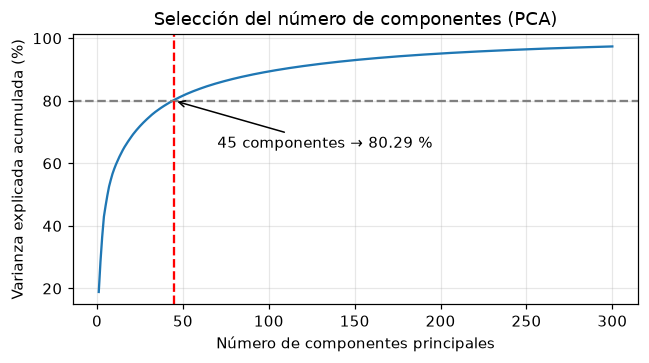

Componentes para el 80 % de la varianza: 45 de 1024 (reducción de dimensión del 95.6 %)
Componentes que exigiría el 95 %: 197

Parecido (kernel RBF) entre una imagen nueva y su vecina de entrenamiento más parecida:
 Dimensión Varianza conservada  d² a la vecina más parecida (mediana) K con γ = 0.1 K con γ = 1.0
        45                80 %                                    7.5       4.7e-01       5.4e-04
       197                95 %                                   88.7       1.4e-04       3.1e-39
      1024     100 % (sin PCA)                                  215.9       4.2e-10       1.7e-94


In [9]:
# =====================================================================================
# QUÉ HACE: (1) curva de varianza explicada acumulada del PCA; (2) número de componentes
# para el 80 % y el 95 %; (3) distancia de una imagen nueva a su vecina más parecida según
# la dimensión, y cuánto vale el kernel RBF con esa distancia.
# IMPORTANTE: todo se ajusta con X_train; X_test solo se transforma.
# =====================================================================================

# (1) PCA con todas las componentes, solo para estudiar la varianza
pca_full = PCA(random_state=SEED).fit(StandardScaler().fit_transform(X_train))
var_acum = np.cumsum(pca_full.explained_variance_ratio_)     # varianza acumulada: 1, 1+2, 1+2+3, ...
N_COMP = int(np.searchsorted(var_acum, VAR_PCA) + 1)         # mínimo número de componentes con ≥ 80 %
N_95 = int(np.searchsorted(var_acum, 0.95) + 1)              # mínimo número de componentes con ≥ 95 %

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(np.arange(1, 301), var_acum[:300] * 100)
ax.axhline(VAR_PCA * 100, ls="--", c="gray"); ax.axvline(N_COMP, ls="--", c="red")
ax.annotate(f"{N_COMP} componentes → {var_acum[N_COMP - 1] * 100:.2f} %", (N_COMP, VAR_PCA * 100),
            xytext=(N_COMP + 25, VAR_PCA * 100 - 15), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Número de componentes principales"); ax.set_ylabel("Varianza explicada acumulada (%)")
ax.set_title("Selección del número de componentes (PCA)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figuras/pca_varianza.png"); plt.show()
print(f"Componentes para el 80 % de la varianza: {N_COMP} de {X_train.shape[1]} "
      f"(reducción de dimensión del {(1 - N_COMP / X_train.shape[1]) * 100:.1f} %)")
print(f"Componentes que exigiría el 95 %: {N_95}\n")

# (3) Distancia² de 1 500 imágenes de prueba a su vecina de entrenamiento más parecida
escalador = StandardScaler().fit(X_train)
S_tr, S_te = escalador.transform(X_train), escalador.transform(X_test[:1500])
filas = []
for n in (N_COMP, N_95, None):            # 45 componentes, 197 componentes y sin PCA
    if n:
        p = PCA(n, whiten=True, random_state=SEED).fit(S_tr)
        A, B = p.transform(S_tr), p.transform(S_te)
    else:
        A, B = S_tr, S_te                 # sin PCA: las 1 024 variables escaladas
    # kneighbors devuelve la distancia a la imagen de entrenamiento más cercana; se eleva al cuadrado
    d2 = np.median(NearestNeighbors(n_neighbors=1).fit(A).kneighbors(B)[0][:, 0] ** 2)
    filas.append({"Dimensión": n or X_train.shape[1],
                  "Varianza conservada": f"{var_acum[n - 1] * 100:.0f} %" if n else "100 % (sin PCA)",
                  "d² a la vecina más parecida (mediana)": round(d2, 1),
                  "K con γ = 0.1": f"{np.exp(-0.1 * d2):.1e}",    # parecido según el kernel RBF
                  "K con γ = 1.0": f"{np.exp(-1.0 * d2):.1e}"})
print("Parecido (kernel RBF) entre una imagen nueva y su vecina de entrenamiento más parecida:")
print(pd.DataFrame(filas).to_string(index=False))

### 4.3 Experimento de control: impacto real de la decisión D4 (PCA)

**Qué se hace:** se entrenan las configuraciones #1 (lineal) y #2 (RBF, γ = 0.1) **sin PCA**, solo con el escalado, y se comparan con los mismos modelos con PCA (sección 5).
**Por qué:** una decisión de preprocesamiento debe justificarse con evidencia y no solo con teoría; este control mide qué se gana y qué se pierde con el PCA. **No forma parte de la tabla del enunciado.**
**Tiempo:** unos 3 minutos; se omite con `EJECUTAR_CONTROL = False`.

In [10]:
# =====================================================================================
# QUÉ HACE: entrena #1 y #2 SIN PCA (solo escalado) para medir el efecto de la decisión D4.
# =====================================================================================
CONTROL = {}
if EJECUTAR_CONTROL:
    for num, params in [(1, dict(kernel="linear", C=1.0)), (2, dict(kernel="rbf", C=1.0, gamma=0.1))]:
        # Mismo modelo que en la sección 5, pero sin el paso de PCA
        pipe_sin_pca = Pipeline([("escalado", StandardScaler()), ("svm", SVC(**params, random_state=SEED))])
        t0 = time.perf_counter()
        pipe_sin_pca.fit(X_train, y_train)
        t_fit = time.perf_counter() - t0
        CONTROL[num] = dict(train=round(accuracy_score(y_train, pipe_sin_pca.predict(X_train)) * 100, 2),
                            test=round(accuracy_score(y_test, pipe_sin_pca.predict(X_test)) * 100, 2),
                            sv=int(pipe_sin_pca[-1].n_support_.sum()),   # vectores de soporte
                            t=round(t_fit, 2))
        print(f"Sin PCA #{num} {params}: train {CONTROL[num]['train']:.2f} % | test {CONTROL[num]['test']:.2f} % | "
              f"SV {CONTROL[num]['sv']} | entrenamiento {CONTROL[num]['t']:.1f} s")
else:
    print("Experimento de control omitido (EJECUTAR_CONTROL = False).")

Sin PCA #1 {'kernel': 'linear', 'C': 1.0}: train 97.26 % | test 86.07 % | SV 2308 | entrenamiento 81.2 s
Sin PCA #2 {'kernel': 'rbf', 'C': 1.0, 'gamma': 0.1}: train 100.00 % | test 38.58 % | SV 10500 | entrenamiento 132.6 s


**Lectura del control** (se compara con la Tabla 1, sección 6):

* **RBF γ = 0.1 sin PCA:** 100 % en entrenamiento, pero un accuracy de prueba cercano al azar (≈ 38.6 %) y **todas** las imágenes de entrenamiento como vectores de soporte. Con 1 024 variables escaladas, la distancia de una imagen nueva a cualquier imagen de entrenamiento es tan grande que el kernel vale casi cero, y el modelo memoriza (el mecanismo se explica en la sección 7.1). Con PCA, la misma configuración alcanza 92.38 % en prueba. **Este es el impacto real de la decisión D4: convierte una configuración inservible en la mejor RBF.**
* **Lineal sin PCA:** accuracy de prueba similar (≈ 86 %), pero con una brecha entrenamiento-prueba mayor (97 % en entrenamiento) y un entrenamiento del orden de 10 veces más lento. *Impacto:* el PCA casi no cambia la capacidad del modelo lineal, pero reduce su sobreajuste y su costo.
* **Conclusión:** el PCA no solo acelera; es lo que hace que los valores de γ fijados por el enunciado sean comparables. El costo es la pérdida del 20 % de la varianza, que no se tradujo en una caída del accuracy.

## 5. Punto 2.1 — Implementación y experimentación

La función `ejecutar_configuracion(num)` concentra todo el flujo de una configuración. Decisiones de diseño:

| Decisión | Causa | Impacto |
|---|---|---|
| Un `Pipeline` completo (escalado → PCA → SVM) por configuración | Que el modelo guardado reciba **píxeles crudos** y aplique por sí mismo el mismo preprocesamiento que en entrenamiento. | El archivo `.joblib` queda listo para ejecutarse sobre imágenes nuevas sin reconstruir pasos a mano (sección 10). |
| Medir por separado el preprocesamiento y el entrenamiento de la SVM | La columna *Tiempo* de la tabla debe reflejar el costo del kernel y de C, no el del PCA, que es idéntico en las cinco configuraciones. | Los tiempos de la Tabla 1 son comparables entre kernels. |
| Una celda por configuración, con fecha/hora, usuario y equipo impresos | El enunciado exige ejecutar manualmente cada configuración y capturarla con marca de tiempo. | Cada salida es directamente la evidencia del informe. |
| Matriz de confusión del conjunto de prueba y reporte por clase | El enunciado y los requerimientos generales piden precisión, recall y matriz de confusión. | Permite ver **qué** clases se confunden, no solo cuántos errores hay. |

In [11]:
# =====================================================================================
# QUÉ HACE: define las 5 configuraciones del enunciado y la función que entrena, evalúa,
# grafica y guarda cada una.
# =====================================================================================

# Las cinco configuraciones de la tabla del enunciado (los nombres de los parámetros son los de SVC)
CONFIGURACIONES = {
    1: dict(nombre="Lineal",  kernel="linear", C=1.0),
    2: dict(nombre="RBF",     kernel="rbf",    C=1.0,  gamma=0.1),
    3: dict(nombre="RBF",     kernel="rbf",    C=1.0,  gamma=1.0),
    4: dict(nombre="RBF",     kernel="rbf",    C=10.0, gamma=1.0),
    5: dict(nombre="Poly(2)", kernel="poly",   C=1.0,  degree=2),
}
RESULTADOS = {}   # métricas de cada configuración (para la tabla y el análisis)
MODELOS = {}      # pipelines entrenados (para el análisis de la sección 7)

def ejecutar_configuracion(num):
    cfg = CONFIGURACIONES[num]
    params = {k: v for k, v in cfg.items() if k != "nombre"}   # solo los hiperparámetros que recibe SVC

    # ---- 1. Encabezado para la captura de pantalla (marca de tiempo, usuario, equipo) ----
    ahora = datetime.now().astimezone()                         # fecha y hora local con zona horaria
    print("=" * 74)
    print(f" CONFIGURACIÓN #{num}: SVM kernel {cfg['nombre']} | {params}")
    print(f" Fecha/hora del sistema: {ahora.strftime('%Y-%m-%d %H:%M:%S %Z (UTC%z)')}")
    print(f" Usuario: {getpass.getuser()}   |   Equipo: {platform.node()}   |   Semilla: {SEED}")
    print("=" * 74)

    # ---- 2. Construcción del pipeline ----
    pipe = Pipeline([
        ("escalado", StandardScaler()),                                        # media 0, desviación 1 por píxel
        ("pca", PCA(n_components=VAR_PCA, whiten=True, random_state=SEED)),    # 1 024 -> 45 componentes blanqueadas
        ("svm", SVC(**params, random_state=SEED)),                             # el clasificador
    ])

    # ---- 3. Entrenamiento, con tiempos medidos por separado ----
    # pipe[:-1] son los pasos de preprocesamiento (escalado + PCA). Se ajustan SOLO con X_train
    # y devuelven las imágenes transformadas Z_train.
    t0 = time.perf_counter()
    Z_train = pipe[:-1].fit_transform(X_train)
    t_pre = time.perf_counter() - t0
    # pipe[-1] es la SVM: se entrena sobre las imágenes ya transformadas. Este es el tiempo de la Tabla 1.
    t0 = time.perf_counter()
    pipe[-1].fit(Z_train, y_train)
    t_svm = time.perf_counter() - t0
    # Como cada paso quedó ajustado dentro del pipeline, pipe.predict() ya aplica escalado -> PCA -> SVM.

    # ---- 4. Métricas ----
    acc_tr = round(accuracy_score(y_train, pipe.predict(X_train)) * 100, 2)   # accuracy de entrenamiento (%)
    y_pred = pipe.predict(X_test)                                              # predicciones sobre prueba
    acc_te = round(accuracy_score(y_test, y_pred) * 100, 2)                    # accuracy de prueba (%)
    sv = pipe[-1].n_support_                                                   # vectores de soporte por clase

    print(f"Componentes PCA usadas      : {pipe.named_steps['pca'].n_components_}")
    print(f"Accuracy entrenamiento      : {acc_tr:.2f} %")
    print(f"Accuracy prueba             : {acc_te:.2f} %")
    print(f"Diferencia train - test     : {acc_tr - acc_te:.2f} puntos porcentuales")
    print(f"Vectores de soporte (total) : {sv.sum()}  -> por clase {dict(zip(map(str, pipe[-1].classes_), sv.tolist()))}")
    print(f"Tiempo de entrenamiento SVM : {t_svm:.3f} s   (preprocesamiento: {t_pre:.3f} s)")
    print("\nReporte de clasificación (conjunto de prueba):")
    # precision = de lo que el modelo llamó clase c, cuánto era c; recall = de lo que era c, cuánto encontró
    print(classification_report(y_test, y_pred, digits=4, zero_division=0))

    # ---- 5. Matriz de confusión (filas = clase real, columnas = clase predicha) ----
    cm = confusion_matrix(y_test, y_pred, labels=CLASES)
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
    extra = f"γ={params['gamma']}" if "gamma" in params else (f"grado={params['degree']}" if "degree" in params else "")
    ax.set_title(f"#{num} {cfg['nombre']} C={params['C']} {extra}\n"
                 f"Test acc = {acc_te:.2f} %  |  {ahora:%Y-%m-%d %H:%M:%S}", fontsize=9)
    plt.tight_layout(); plt.savefig(f"figuras/matriz_confusion_cfg{num}.png"); plt.show()

    # ---- 6. Guardado del modelo entrenado (el pipeline completo, no solo la SVM) ----
    archivo = f"modelos/{PREFIJO}_svm_cfg{num}_{cfg['kernel']}.joblib"
    joblib.dump(pipe, archivo)
    print("Modelo guardado en:", archivo)

    # ---- 7. Registro de resultados para la tabla y el análisis ----
    MODELOS[num] = pipe
    RESULTADOS[num] = {"#": num, "Kernel": cfg["nombre"], "C": params["C"],
                       "Gamma/Degree": params.get("gamma", params.get("degree", "N/A")),
                       "Accuracy Train (%)": acc_tr, "Accuracy Test (%)": acc_te,
                       "Support Vectors": int(sv.sum()), "Tiempo (seg)": round(t_svm, 3),
                       # campos internos (no aparecen en la tabla):
                       "SV por clase": sv.tolist(), "cm": cm.tolist(), "y_pred": y_pred,
                       "pred_test": collections.Counter(y_pred.tolist())}

### Configuración #1 — Kernel lineal, C = 1.0

**Qué cambia y qué se espera antes de ejecutar:** Una sola frontera plana por cada par de clases. *Expectativa:* separa bien *Boot* (silueta muy distinta), pero no la frontera curva entre *Sandal* y *Shoe*; accuracy moderado y poca brecha entre entrenamiento y prueba, porque un hiperplano no tiene capacidad para memorizar.

*Ejecutar esta celda y capturar la salida completa, con el reloj del sistema visible.*

 CONFIGURACIÓN #1: SVM kernel Lineal | {'kernel': 'linear', 'C': 1.0}
 Fecha/hora del sistema: 2026-11-19 15:34:40 -05 (UTC-0500)
 Usuario: ur92   |   Equipo: ms-book   |   Semilla: 3119
Componentes PCA usadas      : 45
Accuracy entrenamiento      : 87.62 %
Accuracy prueba             : 86.69 %
Diferencia train - test     : 0.93 puntos porcentuales
Vectores de soporte (total) : 3345  -> por clase {'Boot': 636, 'Sandal': 1388, 'Shoe': 1321}
Tiempo de entrenamiento SVM : 2.841 s   (preprocesamiento: 0.848 s)

Reporte de clasificación (conjunto de prueba):
              precision    recall  f1-score   support

        Boot     0.9145    0.9340    0.9241      1500
      Sandal     0.8431    0.8167    0.8297      1500
        Shoe     0.8416    0.8500    0.8458      1500

    accuracy                         0.8669      4500
   macro avg     0.8664    0.8669    0.8665      4500
weighted avg     0.8664    0.8669    0.8665      4500



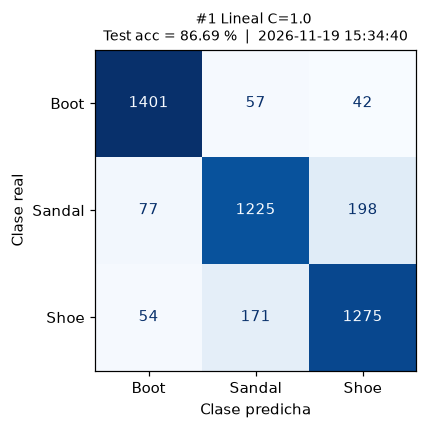

Modelo guardado en: modelos/silva_leon_tobar_gomez_svm_cfg1_linear.joblib


In [12]:
# Entrena, evalúa, grafica y guarda la configuración #1 (ver la función en la celda anterior)
ejecutar_configuracion(1)

### Configuración #2 — Kernel RBF, C = 1.0, γ = 0.1

**Qué cambia y qué se espera antes de ejecutar:** Frontera curva construida con funciones gaussianas centradas en los vectores de soporte; γ = 0.1 les da un alcance amplio, que abarca a varias imágenes vecinas. *Expectativa:* mejor que el lineal en la frontera *Sandal*–*Shoe*, con algo de brecha entre entrenamiento y prueba.

*Ejecutar esta celda y capturar la salida completa, con el reloj del sistema visible.*

 CONFIGURACIÓN #2: SVM kernel RBF | {'kernel': 'rbf', 'C': 1.0, 'gamma': 0.1}
 Fecha/hora del sistema: 2026-11-19 15:34:45 -05 (UTC-0500)
 Usuario: ur92   |   Equipo: ms-book   |   Semilla: 3119
Componentes PCA usadas      : 45
Accuracy entrenamiento      : 98.91 %
Accuracy prueba             : 92.38 %
Diferencia train - test     : 6.53 puntos porcentuales
Vectores de soporte (total) : 5651  -> por clase {'Boot': 1357, 'Sandal': 2054, 'Shoe': 2240}
Tiempo de entrenamiento SVM : 2.623 s   (preprocesamiento: 1.780 s)

Reporte de clasificación (conjunto de prueba):
              precision    recall  f1-score   support

        Boot     0.9732    0.9207    0.9462      1500
      Sandal     0.9532    0.8820    0.9162      1500
        Shoe     0.8582    0.9687    0.9101      1500

    accuracy                         0.9238      4500
   macro avg     0.9282    0.9238    0.9242      4500
weighted avg     0.9282    0.9238    0.9242      4500



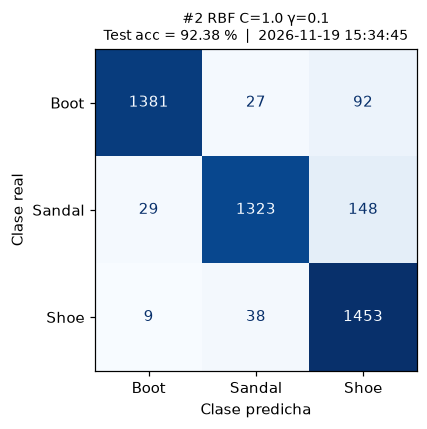

Modelo guardado en: modelos/silva_leon_tobar_gomez_svm_cfg2_rbf.joblib


In [13]:
# Entrena, evalúa, grafica y guarda la configuración #2 (ver la función en la celda anterior)
ejecutar_configuracion(2)

### Configuración #3 — Kernel RBF, C = 1.0, γ = 1.0

**Qué cambia y qué se espera antes de ejecutar:** Alcance 10 veces menor en el exponente. *Expectativa:* cada imagen de entrenamiento influye solo sobre sí misma, por lo que se anticipa memorización: entrenamiento cercano al 100 % y caída fuerte en prueba.

*Ejecutar esta celda y capturar la salida completa, con el reloj del sistema visible.*

 CONFIGURACIÓN #3: SVM kernel RBF | {'kernel': 'rbf', 'C': 1.0, 'gamma': 1.0}
 Fecha/hora del sistema: 2026-11-19 15:34:53 -05 (UTC-0500)
 Usuario: ur92   |   Equipo: ms-book   |   Semilla: 3119
Componentes PCA usadas      : 45
Accuracy entrenamiento      : 99.98 %
Accuracy prueba             : 51.69 %
Diferencia train - test     : 48.29 puntos porcentuales
Vectores de soporte (total) : 10467  -> por clase {'Boot': 3485, 'Sandal': 3487, 'Shoe': 3495}
Tiempo de entrenamiento SVM : 6.164 s   (preprocesamiento: 1.135 s)

Reporte de clasificación (conjunto de prueba):
              precision    recall  f1-score   support

        Boot     0.9958    0.3187    0.4828      1500
      Sandal     0.9574    0.2400    0.3838      1500
        Shoe     0.4083    0.9920    0.5785      1500

    accuracy                         0.5169      4500
   macro avg     0.7872    0.5169    0.4817      4500
weighted avg     0.7872    0.5169    0.4817      4500



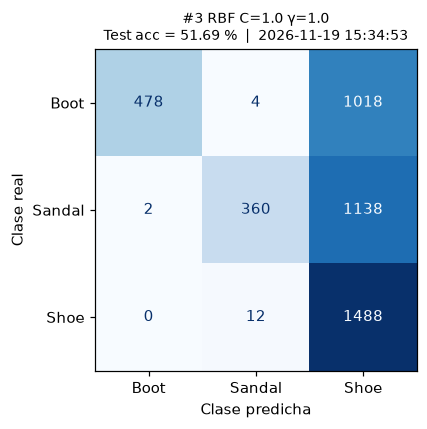

Modelo guardado en: modelos/silva_leon_tobar_gomez_svm_cfg3_rbf.joblib


In [14]:
# Entrena, evalúa, grafica y guarda la configuración #3 (ver la función en la celda anterior)
ejecutar_configuracion(3)

### Configuración #4 — Kernel RBF, C = 10.0, γ = 1.0

**Qué cambia y qué se espera antes de ejecutar:** Igual que la #3, pero penalizando 10 veces más los errores de entrenamiento. *Expectativa:* como la #3 ya casi no comete errores en entrenamiento, aumentar C debería cambiar poco; el problema de la #3 lo causa γ, no C.

*Ejecutar esta celda y capturar la salida completa, con el reloj del sistema visible.*

 CONFIGURACIÓN #4: SVM kernel RBF | {'kernel': 'rbf', 'C': 10.0, 'gamma': 1.0}
 Fecha/hora del sistema: 2026-11-19 15:35:09 -05 (UTC-0500)
 Usuario: ur92   |   Equipo: ms-book   |   Semilla: 3119
Componentes PCA usadas      : 45
Accuracy entrenamiento      : 100.00 %
Accuracy prueba             : 54.42 %
Diferencia train - test     : 45.58 puntos porcentuales
Vectores de soporte (total) : 10462  -> por clase {'Boot': 3481, 'Sandal': 3488, 'Shoe': 3493}
Tiempo de entrenamiento SVM : 6.034 s   (preprocesamiento: 0.878 s)

Reporte de clasificación (conjunto de prueba):
              precision    recall  f1-score   support

        Boot     0.9927    0.3640    0.5327      1500
      Sandal     0.9586    0.2780    0.4310      1500
        Shoe     0.4228    0.9907    0.5926      1500

    accuracy                         0.5442      4500
   macro avg     0.7914    0.5442    0.5188      4500
weighted avg     0.7914    0.5442    0.5188      4500



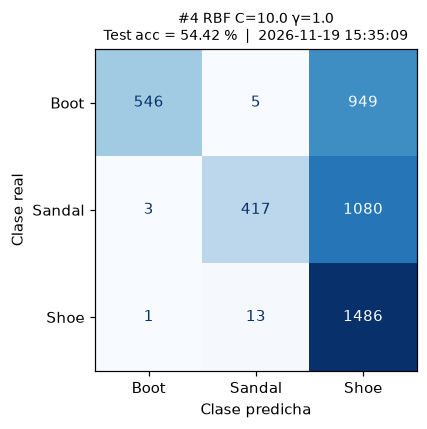

Modelo guardado en: modelos/silva_leon_tobar_gomez_svm_cfg4_rbf.joblib


In [15]:
# Entrena, evalúa, grafica y guarda la configuración #4 (ver la función en la celda anterior)
ejecutar_configuracion(4)

### Configuración #5 — Kernel polinomial de grado 2, C = 1.0

**Qué cambia y qué se espera antes de ejecutar:** Frontera cuadrática: puede curvarse, pero de forma global y suave (no local como el RBF). *Expectativa:* mejor que el lineal y sin memorizar, con complejidad intermedia.

*Ejecutar esta celda y capturar la salida completa, con el reloj del sistema visible.*

 CONFIGURACIÓN #5: SVM kernel Poly(2) | {'kernel': 'poly', 'C': 1.0, 'degree': 2}
 Fecha/hora del sistema: 2026-11-19 15:35:24 -05 (UTC-0500)
 Usuario: ur92   |   Equipo: ms-book   |   Semilla: 3119
Componentes PCA usadas      : 45
Accuracy entrenamiento      : 94.27 %
Accuracy prueba             : 91.89 %
Diferencia train - test     : 2.38 puntos porcentuales
Vectores de soporte (total) : 3967  -> por clase {'Boot': 1056, 'Sandal': 1546, 'Shoe': 1365}
Tiempo de entrenamiento SVM : 1.374 s   (preprocesamiento: 0.916 s)

Reporte de clasificación (conjunto de prueba):
              precision    recall  f1-score   support

        Boot     0.9485    0.9460    0.9473      1500
      Sandal     0.8801    0.9053    0.8925      1500
        Shoe     0.9295    0.9053    0.9173      1500

    accuracy                         0.9189      4500
   macro avg     0.9194    0.9189    0.9190      4500
weighted avg     0.9194    0.9189    0.9190      4500



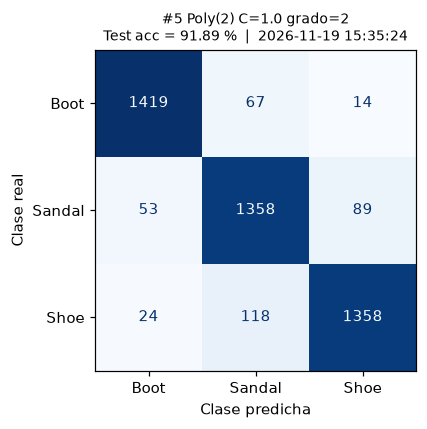

Modelo guardado en: modelos/silva_leon_tobar_gomez_svm_cfg5_poly.joblib


In [16]:
# Entrena, evalúa, grafica y guarda la configuración #5 (ver la función en la celda anterior)
ejecutar_configuracion(5)

## 6. Tabla de experimentos y visualizaciones

**Qué se hace:** se consolidan los resultados de las cinco celdas anteriores en la Tabla 1 (también exportada a CSV para el informe).
**Por qué se genera por código:** se evitan errores de transcripción; cada cifra proviene directamente de la ejecución.

In [17]:
# =====================================================================================
# QUÉ HACE: construye la Tabla 1 con las columnas exactas que pide el enunciado y la
# exporta a CSV para copiarla al informe.
# =====================================================================================
internos = ("SV por clase", "cm", "y_pred", "pred_test")         # campos que no van en la tabla
tabla = pd.DataFrame([{k: v for k, v in RESULTADOS[i].items() if k not in internos} for i in sorted(RESULTADOS)])
tabla.to_csv(f"{PREFIJO}_tabla_experimentos_svm.csv", index=False)
print("Tabla 1: Resultados de las cinco configuraciones SVM (semilla 3119, partición 70/30)")
mostrar_tabla(tabla, {"C": "{:.1f}", "Accuracy Train (%)": "{:.2f}", "Accuracy Test (%)": "{:.2f}", "Tiempo (seg)": "{:.3f}"})

Tabla 1: Resultados de las cinco configuraciones SVM (semilla 3119, partición 70/30)


#,Kernel,C,Gamma/Degree,Accuracy Train (%),Accuracy Test (%),Support Vectors,Tiempo (seg)
1,Lineal,1.0,N/A,87.62,86.69,3345,2.841
2,RBF,1.0,0.100000,98.91,92.38,5651,2.623
3,RBF,1.0,1.000000,99.98,51.69,10467,6.164
4,RBF,10.0,1.000000,100.00,54.42,10462,6.034
5,Poly(2),1.0,2,94.27,91.89,3967,1.374


**Gráfica comparativa.** *Por qué:* la distancia entre la barra azul (entrenamiento) y la naranja (prueba) muestra el sobreajuste de un vistazo, y la línea del azar (33.3 %) indica qué tan cerca está un modelo de no haber aprendido nada. A la derecha, el número de vectores de soporte frente al total de entrenamiento muestra cuánto del conjunto «necesita recordar» cada modelo.

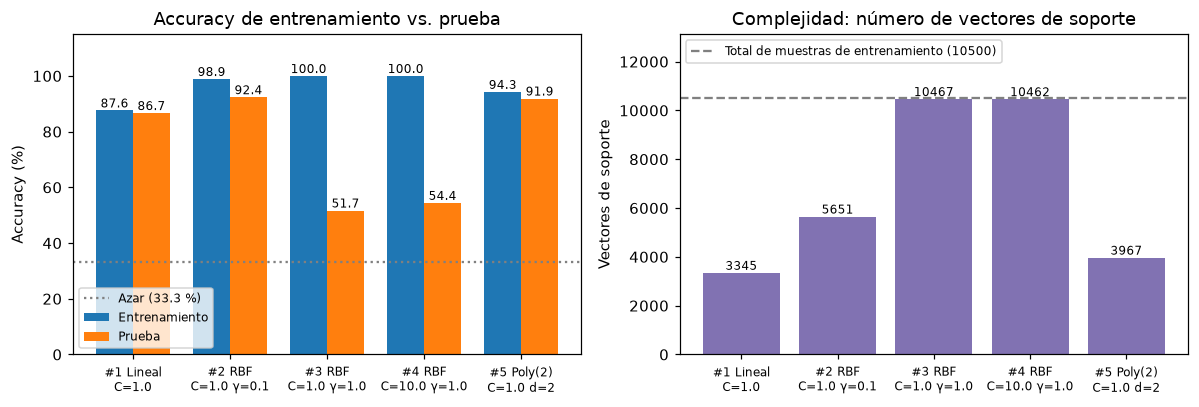

In [18]:
# =====================================================================================
# QUÉ HACE: (izquierda) accuracy de entrenamiento y prueba por configuración;
# (derecha) número de vectores de soporte frente al total de imágenes de entrenamiento.
# =====================================================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
# Etiquetas del eje x, por ejemplo "#2 RBF\nC=1.0 γ=0.1"
etq = [f"#{r['#']} {r['Kernel']}\nC={r['C']}" + ("" if r['Gamma/Degree'] == "N/A" else
       (f" γ={r['Gamma/Degree']}" if r['Kernel'] == "RBF" else f" d={r['Gamma/Degree']}")) for _, r in tabla.iterrows()]
x = np.arange(len(tabla)); w = 0.38                                 # posiciones y ancho de las barras
b1 = axes[0].bar(x - w/2, tabla["Accuracy Train (%)"], w, label="Entrenamiento")
b2 = axes[0].bar(x + w/2, tabla["Accuracy Test (%)"], w, label="Prueba")
axes[0].bar_label(b1, fmt="%.1f", fontsize=8); axes[0].bar_label(b2, fmt="%.1f", fontsize=8)
axes[0].axhline(100/3, ls=":", c="gray", label="Azar (33.3 %)")    # referencia: adivinar al azar
axes[0].set_xticks(x, etq, fontsize=8); axes[0].set_ylabel("Accuracy (%)"); axes[0].set_ylim(0, 115)
axes[0].set_title("Accuracy de entrenamiento vs. prueba"); axes[0].legend(loc="lower left", fontsize=8)
b3 = axes[1].bar(x, tabla["Support Vectors"], color="#8172B2"); axes[1].bar_label(b3, fontsize=8)
axes[1].axhline(len(y_train), ls="--", c="gray", label=f"Total de muestras de entrenamiento ({len(y_train)})")
axes[1].legend(loc="upper left", fontsize=8)
axes[1].set_xticks(x, etq, fontsize=8); axes[1].set_ylabel("Vectores de soporte"); axes[1].set_ylim(0, len(y_train) * 1.25)
axes[1].set_title("Complejidad: número de vectores de soporte")
plt.tight_layout(); plt.savefig("figuras/comparacion_configuraciones.png"); plt.show()

### Visualización de las fronteras de decisión

**Qué se hace:** se proyectan las imágenes a **2 componentes principales** y se entrena cada configuración sobre una submuestra estratificada de 3 000 imágenes de entrenamiento, para dibujar las regiones que asigna cada modelo.
**Por qué en 2D:** una frontera en 45 dimensiones no puede dibujarse; el plano de las dos primeras componentes es la mejor vista bidimensional posible.
**Limitación (impacto en la lectura):** en 2D las clases se solapan mucho más que en 45 dimensiones y las distancias son menores, por lo que el efecto de γ se atenúa. La figura ilustra la **forma** de cada frontera (plana, cuadrática, curva), no reproduce el accuracy de la Tabla 1.

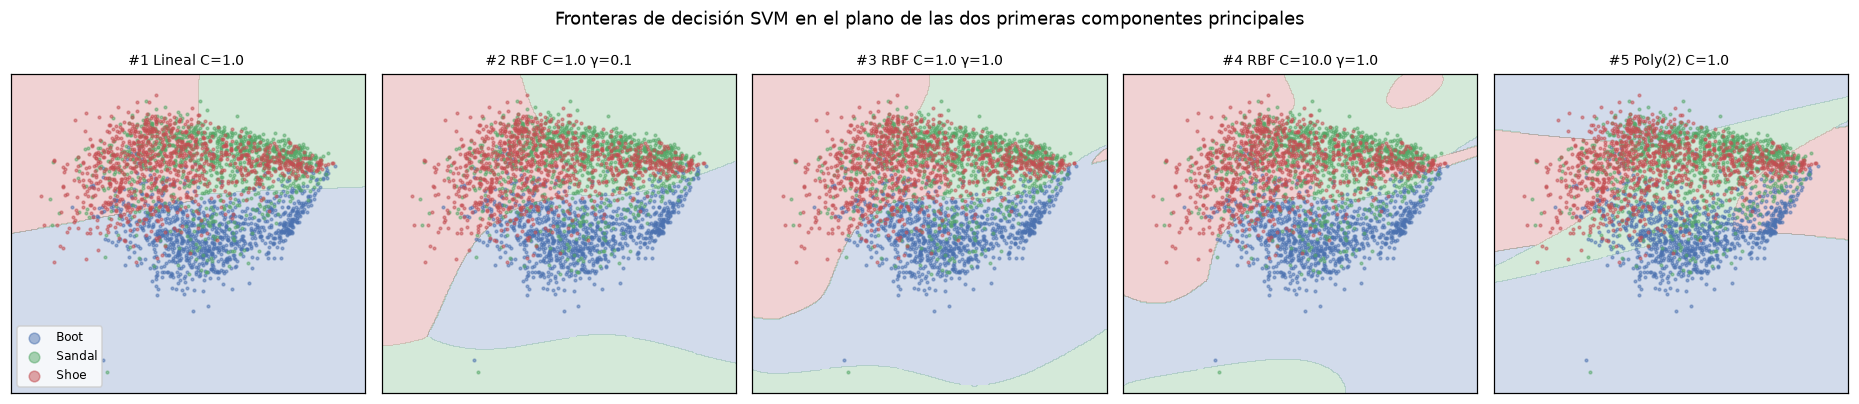

In [19]:
# =====================================================================================
# QUÉ HACE: dibuja las regiones de decisión de cada configuración en un plano 2D.
# PASOS: proyectar a 2 componentes -> entrenar cada SVM en 2D -> evaluarla en una malla de
# puntos del plano -> colorear cada punto según la clase predicha.
# =====================================================================================
# Submuestra estratificada de 3 000 imágenes (para que el dibujo sea rápido y legible)
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=3000, stratify=y_train, random_state=SEED)
proy = Pipeline([("escalado", StandardScaler()), ("pca", PCA(2, whiten=True, random_state=SEED))]).fit(X_train)
Z = proy.transform(X_sub)                                        # cada imagen -> un punto (x, y)
cod = {c: i for i, c in enumerate(CLASES)}
y_num = np.vectorize(cod.get)(y_sub)                             # clases como números 0, 1, 2 (para colorear)
# Malla de 300 x 300 puntos que cubre el plano
xx, yy = np.meshgrid(np.linspace(Z[:, 0].min() - .5, Z[:, 0].max() + .5, 300),
                     np.linspace(Z[:, 1].min() - .5, Z[:, 1].max() + .5, 300))
colores = ["#4C72B0", "#55A868", "#C44E52"]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.7))
for ax, (num, cfg) in zip(axes, CONFIGURACIONES.items()):
    params = {k: v for k, v in cfg.items() if k != "nombre"}
    m = SVC(**params, random_state=SEED).fit(Z, y_num)                     # SVM entrenada en 2D
    zz = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)        # clase de cada punto de la malla
    ax.contourf(xx, yy, zz, alpha=.25, levels=[-.5, .5, 1.5, 2.5], colors=colores)   # regiones coloreadas
    for i, c in enumerate(CLASES):
        ax.scatter(Z[y_num == i, 0], Z[y_num == i, 1], s=3, alpha=.5, c=colores[i], label=c)
    ax.set_title(f"#{num} {cfg['nombre']} C={params['C']} " + (f"γ={params['gamma']}" if "gamma" in params else ""), fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=4, fontsize=8, loc="lower left")
plt.suptitle("Fronteras de decisión SVM en el plano de las dos primeras componentes principales")
plt.tight_layout(); plt.savefig("figuras/fronteras_decision_2D.png"); plt.show()

## 7. Punto 2.2 — Análisis de resultados

### Idea clave: γ define el alcance de cada vector de soporte

En el kernel RBF, cada vector de soporte «vota» por su clase con una fuerza que depende de qué tan parecida es la imagen nueva a él:

$$K(\mathbf{x},\mathbf{x}') = \exp\!\left(-\gamma\,\lVert \mathbf{x}-\mathbf{x}'\rVert^2\right), \qquad f(\mathbf{x}) = \sum_i \alpha_i\, y_i\, K(\mathbf{x}_i, \mathbf{x}) + b.$$

$K$ vale 1 si las dos imágenes son idénticas y decae hacia 0 a medida que se separan; $f(\mathbf{x})$ suma esos votos, cada uno ponderado por el peso $\alpha_i$ del vector de soporte, más un término constante $b$ (intercepto). Una forma intuitiva de verlo: cada vector de soporte es una **lámpara** que ilumina su alrededor, y **γ define qué tan lejos llega la luz**.

* **γ pequeño:** cada lámpara ilumina una zona amplia que incluye a muchas imágenes vecinas. El modelo aprende **regiones** de cada clase y la frontera es suave: **generaliza**.
* **γ grande:** cada lámpara solo se ilumina a sí misma. El modelo recuerda cada imagen de entrenamiento por separado (**memoriza**), y una imagen nueva cae casi siempre en la oscuridad: todos los $K$ valen casi cero, $f(\mathbf{x}) \approx b$, y el modelo responde con la clase que favorece el intercepto, sin mirar la imagen.

Que γ sea «grande» o «pequeño» no depende de su valor aislado, sino de **cuánto se separan las imágenes entre sí**: el mismo γ = 0.1 produce la mejor RBF con 45 componentes y un modelo casi aleatorio con 1 024 variables (sección 4.3). Por eso la celda siguiente mide esas distancias.

**Qué calcula la celda siguiente:**

1. **Sobreajuste:** la diferencia entrenamiento − prueba de cada configuración; qué clases predice el modelo más sobreajustado y de dónde salen sus aciertos.
2. **Escala de distancias:** cuánto se separan dos imágenes cualesquiera y cuánto se separa una imagen de prueba de su vecina más parecida en entrenamiento, y qué similitud $K$ produce cada γ con esas distancias.
3. **Efecto de C frente a γ** entre las configuraciones #2, #3 y #4, y efecto del tipo de kernel.
4. **Complejidad:** vectores de soporte de la configuración lineal, de la mejor RBF y de la polinomial, junto con una prueba estadística (McNemar) para saber si la diferencia de accuracy entre los mejores modelos es real o atribuible al azar de la partición.

In [20]:
# =====================================================================================
# QUÉ HACE: calcula, a partir de los resultados de la sección 5, todas las cifras que
# sustentan las respuestas 7.1, 7.2 y 7.3.
# =====================================================================================
R = RESULTADOS
n_tr, n_te = len(y_train), len(y_test)

def f1_macro(cm):
    # F1 macro a partir de la matriz de confusión: promedio simple del F1 de las 3 clases
    cm = np.array(cm)
    precision = np.diag(cm) / cm.sum(0)       # columnas: lo que el modelo predijo
    recall = np.diag(cm) / cm.sum(1)          # filas: lo que realmente era
    return np.mean(2 * precision * recall / (precision + recall))

# ---------------- 1. SOBREAJUSTE ----------------
print("1) SOBREAJUSTE — brecha (accuracy de entrenamiento − accuracy de prueba), en puntos porcentuales")
brecha = {i: round(R[i]["Accuracy Train (%)"] - R[i]["Accuracy Test (%)"], 2) for i in R}
i_sob = max(brecha, key=brecha.get)          # configuración con la mayor brecha
for i in R:
    print(f"   #{i} {R[i]['Kernel']:<8} C={R[i]['C']:<5} {str(R[i]['Gamma/Degree']):<4}: "
          f"{R[i]['Accuracy Train (%)']:6.2f} − {R[i]['Accuracy Test (%)']:6.2f} = {brecha[i]:6.2f}"
          + ("   <-- máxima" if i == i_sob else ""))
pred = R[i_sob]["pred_test"]
print(f"   Predicciones de #{i_sob} sobre las {n_te} imágenes de prueba (1 500 reales de cada clase): "
      + ", ".join(f"{c} {pred[c]} ({pred[c] / n_te * 100:.1f} %)" for c in CLASES))
print(f"   Vectores de soporte de #{i_sob}: {R[i_sob]['Support Vectors']} de {n_tr} ({R[i_sob]['Support Vectors'] / n_tr * 100:.1f} %)")
svm_s = MODELOS[i_sob][-1]
lejano = np.full((1, MODELOS[i_sob].named_steps["pca"].n_components_), 30.0)   # punto alejado de todas las imágenes
print(f"   Clase que asigna #{i_sob} a una imagen alejada de todas (K ≈ 0, solo cuenta b): {svm_s.predict(lejano)[0]}")

# ---------------- 2. ESCALA DE DISTANCIAS ----------------
print("\n2) ESCALA DE DISTANCIAS en el espacio de la SVM (45 componentes blanqueadas)")
Ztr = MODELOS[2][:-1].transform(X_train)     # imágenes de entrenamiento tras escalado + PCA
Zte = MODELOS[2][:-1].transform(X_test)      # imágenes de prueba con la misma transformación
rng = np.random.default_rng(SEED)
a, b = rng.integers(0, len(Ztr), (2, 20000))                  # 20 000 pares aleatorios
d2_pares = ((Ztr[a] - Ztr[b]) ** 2).sum(1); d2_pares = d2_pares[d2_pares > 0]
d2_vecino = NearestNeighbors(n_neighbors=1).fit(Ztr).kneighbors(Zte[:1500])[0][:, 0] ** 2
med_par, med_vec = np.median(d2_pares), np.median(d2_vecino)
print(f"   Distancia² típica entre dos imágenes cualesquiera     : {med_par:.1f}")
print(f"   Distancia² típica de una imagen nueva a su vecina más parecida: {med_vec:.1f}")
for g in (0.1, 1.0):
    print(f"   γ = {g}: K con la vecina más parecida = {np.exp(-g * med_vec):.2e} | "
          f"K con una imagen cualquiera = {np.exp(-g * med_par):.2e}")
print(f"   Referencia: γ='scale' que usaría sklearn por defecto = {1 / (Ztr.shape[1] * Ztr.var()):.4f}")

# ---------------- 3. EFECTO DE C FRENTE A γ, Y DEL KERNEL ----------------
print("\n3) EFECTO DE LOS HIPERPARÁMETROS sobre el accuracy de prueba")
dg = round(R[3]["Accuracy Test (%)"] - R[2]["Accuracy Test (%)"], 2)    # solo cambia γ
dc = round(R[4]["Accuracy Test (%)"] - R[3]["Accuracy Test (%)"], 2)    # solo cambia C
print(f"   γ 0.1 → 1.0 (C = 1 fijo) : #2 {R[2]['Accuracy Test (%)']:.2f} → #3 {R[3]['Accuracy Test (%)']:.2f} = {dg:+.2f} p.p. ({dg / 100 * n_te:+.0f} imágenes)")
print(f"   C 1 → 10 (γ = 1 fijo)    : #3 {R[3]['Accuracy Test (%)']:.2f} → #4 {R[4]['Accuracy Test (%)']:.2f} = {dc:+.2f} p.p. ({dc / 100 * n_te:+.0f} imágenes)")
print(f"   Relación |Δγ| / |ΔC| = {abs(dg) / abs(dc):.1f} veces")
for i in (3, 4):
    s = MODELOS[i][-1]
    alf = np.abs(s.dual_coef_)                              # pesos α de cada vector de soporte
    rec = np.diag(np.array(R[i]["cm"])) / np.array(R[i]["cm"]).sum(1)
    print(f"   #{i} (C = {s.C}): SV con α en el tope C = {np.isclose(alf, s.C).any(0).mean() * 100:5.2f} % | "
          f"|b| medio = {np.abs(s.intercept_).mean():.4f} | recall " + ", ".join(f"{c} {r:.3f}" for c, r in zip(CLASES, rec)))
print(f"   Tipo de kernel (prueba): lineal {R[1]['Accuracy Test (%)']:.2f} | polinomial {R[5]['Accuracy Test (%)']:.2f} | "
      f"RBF γ=0.1 {R[2]['Accuracy Test (%)']:.2f}")

# ---------------- 4. COMPLEJIDAD ----------------
print("\n4) COMPLEJIDAD")
i_rbf = max((2, 3, 4), key=lambda i: R[i]["Accuracy Test (%)"])        # mejor RBF = mayor accuracy de prueba
conf_ss = lambda cm: np.array(cm)[1, 2] + np.array(cm)[2, 1]            # errores Sandal <-> Shoe
filas = []
for i in (1, 5, i_rbf, 3):
    filas.append({"Config.": f"#{i} {R[i]['Kernel']}", "SV": R[i]["Support Vectors"],
                  "% entrenamiento": round(R[i]["Support Vectors"] / n_tr * 100, 1),
                  "Acc. prueba (%)": R[i]["Accuracy Test (%)"], "F1 macro": round(f1_macro(R[i]["cm"]), 4),
                  "Brecha (p.p.)": brecha[i], "Errores Sandal↔Shoe": conf_ss(R[i]["cm"]),
                  "Tiempo (s)": R[i]["Tiempo (seg)"]})
print(pd.DataFrame(filas).to_string(index=False))
sv1, svr, sv5 = R[1]["Support Vectors"], R[i_rbf]["Support Vectors"], R[5]["Support Vectors"]
print(f"   Mejor RBF: #{i_rbf} | RBF − lineal = {svr - sv1} SV ({svr / sv1:.2f} veces) | "
      f"RBF − polinomial = {svr - sv5} SV (la RBF usa {(svr / sv5 - 1) * 100:.1f} % más)")

# Prueba de McNemar: compara dos modelos sobre las MISMAS imágenes de prueba, contando solo
# las imágenes en que discrepan. Si ambos fueran igual de buenos, esos desacuerdos se
# repartirían 50/50; el valor p mide qué tan raro sería el reparto observado si fuera así.
def mcnemar(i, j):
    ok_i, ok_j = R[i]["y_pred"] == y_test, R[j]["y_pred"] == y_test
    solo_i, solo_j = int((ok_i & ~ok_j).sum()), int((~ok_i & ok_j).sum())
    return solo_i, solo_j, binomtest(solo_i, solo_i + solo_j, 0.5).pvalue
for i, j in ((i_rbf, 5), (i_rbf, 1), (5, 1)):
    si, sj, p = mcnemar(i, j)
    print(f"   McNemar #{i} vs #{j}: solo #{i} acierta {si} | solo #{j} acierta {sj} | valor p = {p:.3g}"
          + ("  -> diferencia NO significativa" if p >= 0.05 else "  -> diferencia significativa"))

1) SOBREAJUSTE — brecha (accuracy de entrenamiento − accuracy de prueba), en puntos porcentuales
   #1 Lineal   C=1.0   N/A :  87.62 −  86.69 =   0.93
   #2 RBF      C=1.0   0.1 :  98.91 −  92.38 =   6.53
   #3 RBF      C=1.0   1.0 :  99.98 −  51.69 =  48.29   <-- máxima
   #4 RBF      C=10.0  1.0 : 100.00 −  54.42 =  45.58
   #5 Poly(2)  C=1.0   2   :  94.27 −  91.89 =   2.38
   Predicciones de #3 sobre las 4500 imágenes de prueba (1 500 reales de cada clase): Boot 480 (10.7 %), Sandal 376 (8.4 %), Shoe 3644 (81.0 %)
   Vectores de soporte de #3: 10467 de 10500 (99.7 %)
   Clase que asigna #3 a una imagen alejada de todas (K ≈ 0, solo cuenta b): Shoe

2) ESCALA DE DISTANCIAS en el espacio de la SVM (45 componentes blanqueadas)
   Distancia² típica entre dos imágenes cualesquiera     : 57.5
   Distancia² típica de una imagen nueva a su vecina más parecida: 7.5
   γ = 0.1: K con la vecina más parecida = 4.71e-01 | K con una imagen cualquiera = 3.19e-03
   γ = 1.0: K con la vecina más pa

### 7.1 Sobreajuste (0.2 pts)

**Pregunta que responde:** ¿el modelo aprendió la forma de cada clase o memorizó las imágenes de entrenamiento?

**Concepto.** En una SVM, el sobreajuste ocurre cuando la frontera de decisión se vuelve tan irregular y local que se ajusta a las particularidades de las imágenes de entrenamiento (su posición exacta, su iluminación, su ruido) en lugar de capturar la estructura que comparten todas las imágenes de una clase. Se detecta comparando el accuracy de entrenamiento con el de prueba: una brecha grande significa que el modelo rinde en lo que ya vio, pero no en lo nuevo.

**Respuesta.** La configuración con mayor sobreajuste es la **#3 (RBF, C = 1.0, γ = 1.0)**:

$$\Delta_{\#3} = \text{Acc}_{train} - \text{Acc}_{test} = 99.98\,\% - 51.69\,\% = \mathbf{48.29 \text{ puntos porcentuales}}$$

**Diagnóstico de las cinco configuraciones**

| # | Train (%) | Test (%) | Brecha (p.p.) | Diagnóstico |
|---|---|---|---|---|
| 3 | 99.98 | 51.69 | **48.29** | Sobreajuste severo: memorización |
| 4 | 100.00 | 54.42 | 45.58 | Sobreajuste severo: comparte la causa de la #3 (γ = 1.0) |
| 2 | 98.91 | 92.38 | 6.53 | Sobreajuste leve: ajusta casi todo el entrenamiento, pero conserva una alta capacidad de generalización |
| 5 | 94.28 | 91.89 | 2.39 | Ajuste equilibrado: buen desempeño con la brecha más pequeña entre los modelos no lineales |
| 1 | 87.64 | 86.73 | 0.91 | Subajuste leve: la brecha es mínima, pero tiene el accuracy de entrenamiento más bajo de todos; un hiperplano no alcanza a separar ni siquiera las imágenes que ve |

**Por qué ocurrió en la #3.** En términos de la intuición de las lámparas, con γ = 1.0 cada imagen de entrenamiento solo se ilumina a sí misma. La celda anterior lo cuantifica: la distancia cuadrática típica de una imagen de prueba a su vecina más parecida es 7.5, y con γ = 1.0 eso da $K \approx 5 \times 10^{-4}$; con una imagen cualquiera, $K \approx 10^{-25}$. El modelo no aprende cómo es una bota, sino cómo son **esas 10 500 imágenes concretas**. El mecanismo se ve en tres pasos:

1. **Memoriza el entrenamiento.** Como ninguna imagen se parece a otra, la SVM no puede resumir cada clase con unos pocos ejemplos representativos y termina usando **10 467 de las 10 500 imágenes (99.7 %) como vectores de soporte**: guarda prácticamente todo el conjunto. Así logra el 99.98 % en entrenamiento: cada imagen se reconoce a sí misma.
2. **Ante una imagen nueva, no recibe votos.** Una imagen de prueba cae en la oscuridad: todos los términos $\alpha_i y_i K(\mathbf{x}_i,\mathbf{x})$ son casi cero y la decisión queda reducida al intercepto, $f(\mathbf{x}) \approx b$. La predicción deja de depender de la imagen.
3. **Responde una clase por defecto.** Los interceptos de los tres clasificadores uno-contra-uno favorecen a *Shoe* (una imagen alejada de todas se clasifica como *Shoe*), y por eso el modelo asigna esa clase al **81.0 % de las imágenes de prueba** (3 644 de 4 500). El recall de *Shoe* es 0.992, pero el de *Boot* cae a 0.319 y el de *Sandal* a 0.240 (matriz de confusión #3). El 51.69 % no refleja reconocimiento: proviene de acertar las 1 488 imágenes de *Shoe* por defecto y de las pocas imágenes de las otras clases que sí tienen una vecina casi idéntica en entrenamiento.

**Contraste que confirma la causa.** La #2 tiene el mismo C y solo cambia γ a 0.1: su luz alcanza a la vecina más parecida con $K \approx 0.47$, usa 5 651 vectores de soporte en lugar de 10 467 y su brecha baja a 6.53 p.p. La #4, que mantiene γ = 1.0 y solo sube C, sigue igual de sobreajustada.

**Impacto práctico.** Si el modelo #3 se usara en un sistema real, etiquetaría como «zapato» a 4 de cada 5 imágenes, sin importar lo que mostraran. Su 99.98 % de entrenamiento es engañoso: **un accuracy de entrenamiento alto no indica un buen modelo**, y por eso la evaluación siempre debe hacerse sobre datos no vistos. En el otro extremo, el lineal muestra que una brecha pequeña tampoco basta: es estable, pero se queda corto en ambos conjuntos.

### 7.2 Impacto de hiperparámetros (0.2 pts)

**Pregunta que responde:** entre C y γ, ¿cuál controla realmente el comportamiento del kernel RBF?

**Concepto.** Los hiperparámetros de una SVM actúan sobre dos aspectos distintos del modelo. Unos definen la **forma geométrica** de la frontera de decisión: el tipo de kernel, el grado del polinomio y γ, que fija el alcance de cada vector de soporte. Otro define la **tolerancia a los errores**: C, que regula el equilibrio entre un margen amplio y un ajuste estricto al entrenamiento ($0 \le \alpha_i \le C$); un C alto castiga más cada imagen de entrenamiento mal clasificada o dentro del margen. La forma determina qué fronteras son posibles y la tolerancia solo elige entre ellas, por lo que cabe esperar que γ domine.

Entre las configuraciones #2, #3 y #4 cada hiperparámetro cambia **uno a la vez**, lo que permite aislar su efecto.

**Respuesta.** **γ fue el hiperparámetro de mayor impacto**, por un factor de aproximadamente 15:

| Cambio | Accuracy de prueba | Variación |
|---|---|---|
| γ: 0.1 → 1.0 (#2 → #3, C = 1.0 fijo) | 92.38 % → 51.69 % | **−40.69 p.p.** (1 831 imágenes de prueba que pasan de bien a mal clasificadas) |
| C: 1.0 → 10.0 (#3 → #4, γ = 1.0 fijo) | 51.69 % → 54.42 % | **+2.73 p.p.** (123 imágenes) |

Ambos hiperparámetros se multiplicaron por 10, pero el cambio en γ movió el accuracy 14.9 veces más que el cambio en C.

**Por qué γ pesa tanto más que C.**

* **γ cambia la forma del modelo.** Con γ = 0.1 las lámparas alcanzan a las imágenes vecinas y el modelo forma regiones; con γ = 1.0 cada lámpara se ilumina solo a sí misma y el modelo memoriza (sección 7.1). Es como elegir la escala de un mapa: con la escala equivocada no se distingue nada, por mucho cuidado que se ponga después.
* **C solo ajusta la tolerancia, y con γ = 1.0 ya no había errores que tolerar.** El modelo #3 clasificaba bien el 99.98 % del entrenamiento con C = 1.0: solo quedaban **2 imágenes** mal clasificadas. Subir C a 10.0 corrige esas 2 (100.00 %), pero no puede arreglar la causa del fallo, que es el alcance del kernel.

**Por qué C mejoró aun así 2.73 p.p.** Con C = 1.0, el 50.2 % de los vectores de soporte tenía su peso α topado en el máximo permitido; con C = 10.0 ese tope deja de ser activo (0.01 %). El reajuste de los pesos reduce la magnitud de los interceptos (|b| medio de 0.0256 a 0.0173), de modo que la «respuesta por defecto» (*Shoe*) pesa un poco menos y algunas imágenes con una vecina muy cercana logran clasificarse por esa vecina: el recall de *Boot* sube de 0.319 a 0.364 y el de *Sandal* de 0.240 a 0.278. Es una mejora marginal: la #4 sigue sobreajustada (brecha de 45.58 p.p.) y conserva casi los mismos vectores de soporte (10 462 frente a 10 467).

**Efecto del tipo de kernel.** Aunque la pregunta se centra en C y γ, la Tabla 1 también muestra el efecto del kernel, que es otro hiperparámetro de forma:

* **Lineal (#1), 86.73 %:** solo fronteras planas; insuficiente para separar *Sandal* de *Shoe*.
* **Polinomial de grado 2 (#5), 91.89 %:** introduce interacciones cuadráticas entre las componentes; la frontera se curva de forma global y controlada, con un comportamiento estable (brecha de 2.39 p.p.).
* **RBF con γ = 0.1 (#2), 92.38 %:** fronteras curvas y flexibles, construidas localmente; alcanza el mayor accuracy cuando γ está bien calibrado.

El salto de lineal a no lineal (+5.16 p.p. con el polinomial, +5.65 p.p. con el RBF) es mucho mayor que la diferencia entre los dos kernels no lineales (0.49 p.p.). **La decisión más importante es permitir una frontera no lineal; cuál kernel no lineal se use importa menos, siempre que sus hiperparámetros estén en un rango razonable.**

**Impacto práctico.** Al ajustar una SVM RBF, **γ debe elegirse primero**, en relación con la escala de distancias de los datos (aquí, el valor de referencia de sklearn sería γ ≈ 0.022); C se afina después. Ajustar C con un γ equivocado es optimizar el detalle de un modelo que falla en lo estructural.

**Alcance de la conclusión.** El efecto de C solo se midió con γ = 1.0, una región en la que el kernel está degenerado. Con un γ adecuado, como 0.1, C podría tener un efecto mayor; comprobarlo requeriría una configuración adicional (C = 10.0, γ = 0.1), que no forma parte de la tabla solicitada.

### 7.3 Complejidad del modelo (0.1 pts)

**Pregunta que responde:** ¿cuánto tiene que «recordar» cada modelo para clasificar y qué se gana a cambio?

**Concepto.** En una SVM, los vectores de soporte son las imágenes de entrenamiento que quedan sobre el margen o del lado equivocado de la frontera: son las únicas que definen la frontera, y el resto se descarta después del entrenamiento. Su número es un indicador directo de la complejidad del modelo por tres razones: (a) cuanto más irregular es la frontera, más puntos se necesitan para sostenerla; (b) predecir una imagen nueva exige calcular el kernel entre ella y **cada** vector de soporte, de modo que el costo de inferencia y la memoria crecen con su número; y (c) cuando el número se acerca al 100 % del entrenamiento, el modelo ya no selecciona un subconjunto de puntos críticos, sino que recuerda casi todo el conjunto, señal de memorización (#3 y #4).

**Respuesta (comparación que pide el enunciado: lineal frente a la mejor RBF).** La mejor RBF es la **#2** (γ = 0.1; 92.38 % en prueba).

| | Lineal #1 | RBF #2 |
|---|---|---|
| Vectores de soporte | 3 345 (31.9 % del entrenamiento) | **5 651** (53.8 %) |
| Accuracy de prueba | 86.73 % | **92.38 %** |
| Errores *Sandal* ↔ *Shoe* | 367 | **186** |

El modelo RBF necesita **2 306 vectores de soporte más, 1.69 veces los del lineal**. Esta diferencia implica:

1. **El RBF compra precisión con complejidad.** El lineal solo traza fronteras planas; el RBF construye fronteras curvas sumando funciones gaussianas locales, y cada curva adicional requiere imágenes que la sostengan. Esa flexibilidad es la que se necesita en la frontera *Sandal*–*Shoe*: los errores entre ambas clases bajan a la mitad (de 367 a 186) y el accuracy de prueba sube 5.65 p.p. (254 imágenes más bien clasificadas). La prueba de McNemar confirma que la mejora es real (valor p ≈ 10⁻²⁷), y la brecha moderada de la #2 (6.53 p.p.) indica que la complejidad adicional se convirtió en generalización y no en memorización.
2. **El costo de predecir crece con los vectores de soporte.** El RBF compara cada imagen nueva con sus 5 651 vectores de soporte. El lineal, en cambio, puede resumirse en 3 hiperplanos (3 × (45 + 1) = 138 números), y su costo de predicción no depende de cuántos vectores de soporte tenga.
3. **El número de vectores de soporte revela la dificultad del problema.** Incluso el lineal conserva el 31.9 % del entrenamiento: una gran parte de las imágenes queda cerca de alguna frontera, porque las clases se solapan en el espacio de píxeles. En todos los modelos útiles, *Boot* es la clase con menos vectores de soporte (637 en el lineal y 1 357 en la #2), lo que confirma la predicción del EDA de que es la más fácil de separar.

**¿Y el modelo #5?** El enunciado pide comparar el lineal con la mejor RBF, pero el modelo polinomial de grado 2 es necesario para completar el análisis de complejidad: es el segundo modelo más simple y obtiene casi el mismo accuracy que la mejor RBF.

| Configuración | Vectores de soporte | % entrenamiento | Acc. prueba | F1 macro | Brecha | Errores *Sandal* ↔ *Shoe* |
|---|---|---|---|---|---|---|
| #1 Lineal | 3 345 | 31.9 % | 86.73 % | 0.8670 | 0.91 p.p. | 367 |
| **#5 Poly(2)** | **3 967** | **37.8 %** | **91.89 %** | **0.9190** | **2.39 p.p.** | 207 |
| #2 RBF γ = 0.1 | 5 651 | 53.8 % | 92.38 % | 0.9242 | 6.53 p.p. | 186 |

* **Accuracy equivalente.** La #2 supera a la #5 por 0.49 p.p. (22 imágenes de 4 500). Sin embargo, de las 4 500 imágenes de prueba, 184 solo las acierta la #2 y 162 solo las acierta la #5; según la prueba de McNemar (valor p = 0.26), una diferencia así es compatible con el azar de la partición. **Con esta evidencia no puede afirmarse que la #2 sea mejor que la #5.** Ambas superan al lineal de forma significativa.
* **Menor complejidad.** La #5 usa 1 684 vectores de soporte menos (≈ 30 % menos); dicho de otro modo, la #2 necesita un 42.5 % más de vectores de soporte para ganar 0.49 p.p. Además, en la ejecución de referencia la #5 fue la configuración más rápida de entrenar (ver Tabla 1).
* **Por qué el polinomial necesita menos vectores de soporte.** Su frontera es una sola función cuadrática global: no necesita ubicar «lámparas» a lo largo de toda la frontera, como el RBF. Por la misma razón, al igual que el lineal, puede expresarse con un número fijo de coeficientes (con 45 componentes, un polinomio de grado 2 tiene 1 081 términos por par de clases), independiente del tamaño del entrenamiento.
* **Mayor estabilidad.** Su brecha (2.39 p.p.) es menos de la mitad de la de la #2 (6.53 p.p.): su accuracy de prueba es una estimación más confiable de lo que rendirá con imágenes nuevas.
* **Donde la #2 sí es mejor.** La #2 distingue mejor la clase *Sandal* (F1 de 0.9162 frente a 0.8925) y comete menos errores *Sandal* ↔ *Shoe* (186 frente a 207). La #5 es ligeramente mejor en *Boot* (0.9473 frente a 0.9462) y en *Shoe* (0.9173 frente a 0.9101).

**Conclusión.** Si el criterio es únicamente el accuracy de prueba, la mejor configuración es la #2. Si se considera el conjunto de accuracy, complejidad y estabilidad, **la #5 (polinomial de grado 2) es el modelo recomendado**: ofrece un desempeño estadísticamente equivalente con un 30 % menos de vectores de soporte, un entrenamiento más rápido y la menor brecha entre los modelos no lineales. La #2 solo sería preferible si la clasificación de sandalias fuera prioritaria o si una validación cruzada confirmara que su ventaja de 0.49 p.p. es consistente.

### 7.4 Síntesis: qué se aprende del problema

* **El problema es no lineal, pero de forma suave.** La frontera lineal se queda corta (86.73 %), mientras que las fronteras curvas suaves (polinomio de grado 2 y RBF con γ = 0.1) alcanzan alrededor del 92 %. Las fronteras extremadamente locales (γ = 1.0) fracasan. Las clases forman regiones amplias y continuas en el espacio de imágenes, no puntos aislados.
* **En el kernel RBF, la escala lo es todo.** El mismo γ = 0.1 produce la mejor RBF con PCA (92.38 %) y un modelo casi aleatorio sin PCA (sección 4.3). Un hiperparámetro no es «grande» ni «pequeño» por sí mismo: lo es en relación con las distancias entre los datos. Por eso el preprocesamiento y γ deben decidirse juntos.
* **Más complejidad no implica un mejor modelo.** La RBF #2 usa un 42.5 % más de vectores de soporte que el polinomial #5 sin una ventaja estadísticamente significativa; y las RBF con γ = 1.0, las más complejas de todas, son las peores en prueba.
* **El límite está en la representación.** La confusión residual *Sandal*–*Shoe* en todos los modelos útiles indica que los píxeles en gris a 32 × 32 no capturan bien el rasgo que distingue a esas clases (las aberturas). Mejorar la representación, por ejemplo con las características que aprende una red convolucional (punto 4 del taller), probablemente aporte más que seguir ajustando la SVM.

## 8. Limitaciones y recomendaciones técnicas

| Limitación | Causa | Impacto | Recomendación |
|---|---|---|---|
| Una sola partición y hiperparámetros fijos | El enunciado fija las cinco configuraciones y la partición 70/30. | No hay estimación de variabilidad: la diferencia de 0.49 p.p. entre #2 y #5 no es significativa (McNemar, p = 0.26). | `GridSearchCV` con `StratifiedKFold` (k = 5) sobre entrenamiento, con γ ∈ {0.005, 0.01, 0.02, 0.05, 0.1} (alrededor de γ='scale' ≈ 0.022) y C ∈ {0.1, 1, 10, 100}; reportar media ± desviación estándar antes de evaluar en prueba. |
| Representación por píxeles (gris, 32 × 32, 80 % de varianza) | Necesaria para que `SVC` sea tratable y γ tenga sentido (sección 4). | Se pierden color y detalle fino; el modelo es sensible a traslaciones y cambios de escala del calzado. | Usar descriptores de forma (HOG) o *embeddings* de una CNN preentrenada como entrada de la SVM. |
| Confusión *Sandal*–*Shoe* | Perfiles similares; las aberturas de la sandalia se diluyen a 32 × 32. | Es la principal fuente de error de los modelos útiles (186 errores en la #2 y 207 en la #5). | Evaluar una resolución mayor (por ejemplo, 64 × 64), verificando el aumento del tiempo de entrenamiento. |
| Costo de `SVC(Support Vector Classifier)` | El entrenamiento crece entre cuadrática y cúbicamente con el número de muestras. | Con conjuntos mucho más grandes sería impráctico. | Preferir el polinomial de grado 2 o aproximar el kernel (`Nystroem` + `LinearSVC`). |
| Interpretabilidad | La decisión depende de miles de vectores de soporte y del kernel. | No hay reglas directas que expliquen una predicción. | Inspeccionar los vectores de soporte con mayor peso α por clase. |
| Duplicados en *Boot* | Repetidos en el dataset original. | Despreciable (como máximo 0.04 p.p.). | Eliminarlos antes de la partición en un trabajo posterior. |

## 9. Verificación de reproducibilidad

**Por qué existe esta celda:** las respuestas de la sección 7 están escritas con las cifras de una ejecución de referencia con la semilla 3119. El accuracy y los vectores de soporte son deterministas con los mismos datos y la misma semilla, pero podrían variar con otra versión del dataset o de las librerías. La celda compara la ejecución actual con esas cifras.
**Impacto:** si muestra ✔, el texto del análisis corresponde exactamente a la ejecución entregada; si muestra ⚠, indica qué valores del texto deben actualizarse. La celda también comprueba que las conclusiones de la sección 7 se mantienen: con otras versiones de numpy o scikit-learn pueden cambiar unas pocas imágenes (por ejemplo, en el modelo lineal), sin alterar las conclusiones. Los tiempos no se verifican porque dependen del equipo.

In [21]:
# =====================================================================================
# QUÉ HACE: compara el accuracy y los vectores de soporte de esta ejecución con las cifras
# citadas en la sección 7 (valores de referencia).
# =====================================================================================
REFERENCIA = {
 "1": {
  "Accuracy Train (%)": 87.64,
  "Accuracy Test (%)": 86.73,
  "Support Vectors": 3345
 },
 "2": {
  "Accuracy Train (%)": 98.91,
  "Accuracy Test (%)": 92.38,
  "Support Vectors": 5651
 },
 "3": {
  "Accuracy Train (%)": 99.98,
  "Accuracy Test (%)": 51.69,
  "Support Vectors": 10467
 },
 "4": {
  "Accuracy Train (%)": 100.0,
  "Accuracy Test (%)": 54.42,
  "Support Vectors": 10462
 },
 "5": {
  "Accuracy Train (%)": 94.28,
  "Accuracy Test (%)": 91.89,
  "Support Vectors": 3967
 }
}

if REFERENCIA is None:
    print("Sin valores de referencia.")
else:
    difs = []
    for i in RESULTADOS:
        for k in ("Accuracy Train (%)", "Accuracy Test (%)", "Support Vectors"):
            if abs(RESULTADOS[i][k] - REFERENCIA[str(i)][k]) > 1e-9:
                difs.append(f"#{i} {k}: actual {RESULTADOS[i][k]} vs texto {REFERENCIA[str(i)][k]}")
    print("✔ Todas las cifras de accuracy y vectores de soporte coinciden con las citadas en el análisis."
          if not difs else "⚠ Cifras distintas a las del análisis (actualizar el texto):\n  " + "\n  ".join(difs))

    # Además de las cifras exactas, se comprueba que las CONCLUSIONES de la sección 7 se mantienen
    R = RESULTADOS
    conclusiones = {
        "7.1 La configuración con mayor sobreajuste es la #3":
            max(R, key=lambda i: R[i]["Accuracy Train (%)"] - R[i]["Accuracy Test (%)"]) == 3,
        "7.2 γ tiene más impacto que C en el accuracy de prueba":
            abs(R[3]["Accuracy Test (%)"] - R[2]["Accuracy Test (%)"]) > abs(R[4]["Accuracy Test (%)"] - R[3]["Accuracy Test (%)"]),
        "7.3 La mejor RBF es la #2 y usa más vectores de soporte que la lineal":
            max((2, 3, 4), key=lambda i: R[i]["Accuracy Test (%)"]) == 2 and R[2]["Support Vectors"] > R[1]["Support Vectors"],
        "7.3 La diferencia #2 vs #5 no es significativa (McNemar p ≥ 0.05)": mcnemar(2, 5)[2] >= 0.05,
    }
    print("\nConclusiones del análisis:")
    for texto, ok in conclusiones.items():
        print(("  ✔ " if ok else "  ⚠ NO se cumple: ") + texto)

⚠ Cifras distintas a las del análisis (actualizar el texto):
  #1 Accuracy Train (%): actual 87.62 vs texto 87.64
  #1 Accuracy Test (%): actual 86.69 vs texto 86.73
  #5 Accuracy Train (%): actual 94.27 vs texto 94.28

Conclusiones del análisis:
  ✔ 7.1 La configuración con mayor sobreajuste es la #3
  ✔ 7.2 γ tiene más impacto que C en el accuracy de prueba
  ✔ 7.3 La mejor RBF es la #2 y usa más vectores de soporte que la lineal
  ✔ 7.3 La diferencia #2 vs #5 no es significativa (McNemar p ≥ 0.05)


## 10. Uso de los modelos entrenados

**Qué es un archivo `.joblib`.** No es un documento que se abra con un editor (VS Code no puede mostrarlo, igual que no puede mostrar un `.h5` de Keras): es el **objeto de Python ya entrenado**, el pipeline escalado → PCA → SVM con todos sus parámetros aprendidos (medias, componentes principales, vectores de soporte, pesos α e interceptos), guardado en binario. Se «abre» cargándolo con `joblib.load()` y se ejecuta con `.predict()`.

**Requisito:** cargarlo con la misma versión de scikit-learn con la que se guardó. Por eso se guarda junto a los modelos un archivo de metadatos con las versiones y el preprocesamiento exacto.

**Qué demuestran las siguientes celdas:** que los cinco archivos se cargan desde el disco (no desde la memoria del notebook), que reproducen exactamente el accuracy de prueba de la Tabla 1, y que clasifican imágenes a partir de los archivos `.jpg` originales.

In [22]:
# =====================================================================================
# QUÉ HACE: (1) guarda los metadatos necesarios para reutilizar los modelos;
# (2) carga cada modelo DESDE EL DISCO y comprueba que reproduce su accuracy de prueba.
# =====================================================================================

# ---- 1. Metadatos: versiones y preprocesamiento exacto que espera cada modelo ----
metadatos = {"descripcion": "Pipeline StandardScaler -> PCA(80 % varianza, whiten) -> SVC",
             "entrada": f"imagen en escala de grises ('L'), redimensionada a {IMG_SIZE}x{IMG_SIZE}, "
                        f"valores /255, aplanada a un vector de {IMG_SIZE * IMG_SIZE}",
             "clases": CLASES, "semilla": SEED, "origen_datos": ORIGEN, "python": platform.python_version(),
             "scikit_learn": sklearn.__version__, "numpy": np.__version__, "pillow": Image.__version__,
             "modelos": {f"cfg{i}": {"archivo": f"{PREFIJO}_svm_cfg{i}_{CONFIGURACIONES[i]['kernel']}.joblib",
                                     **{k: RESULTADOS[i][k] for k in ("Kernel", "C", "Gamma/Degree",
                                        "Accuracy Test (%)", "Support Vectors")}} for i in RESULTADOS}}
with open(f"modelos/{PREFIJO}_svm_metadatos.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

# ---- 2. Cargar cada modelo desde su archivo y evaluarlo de nuevo ----
for i, cfg in CONFIGURACIONES.items():
    archivo = f"modelos/{PREFIJO}_svm_cfg{i}_{cfg['kernel']}.joblib"
    modelo = joblib.load(archivo)                                  # así se "abre" un .joblib
    acc = round(accuracy_score(y_test, modelo.predict(X_test)) * 100, 2)
    estado = "✔" if acc == RESULTADOS[i]["Accuracy Test (%)"] else "⚠"
    print(f"{estado} {archivo:<58} {os.path.getsize(archivo) / 1e6:5.2f} MB | accuracy de prueba = {acc:.2f} %")

✔ modelos/silva_leon_tobar_gomez_svm_cfg1_linear.joblib       1.54 MB | accuracy de prueba = 86.69 %
✔ modelos/silva_leon_tobar_gomez_svm_cfg2_rbf.joblib          2.45 MB | accuracy de prueba = 92.38 %
✔ modelos/silva_leon_tobar_gomez_svm_cfg3_rbf.joblib          4.36 MB | accuracy de prueba = 51.69 %
✔ modelos/silva_leon_tobar_gomez_svm_cfg4_rbf.joblib          4.36 MB | accuracy de prueba = 54.42 %
✔ modelos/silva_leon_tobar_gomez_svm_cfg5_poly.joblib         1.79 MB | accuracy de prueba = 91.89 %


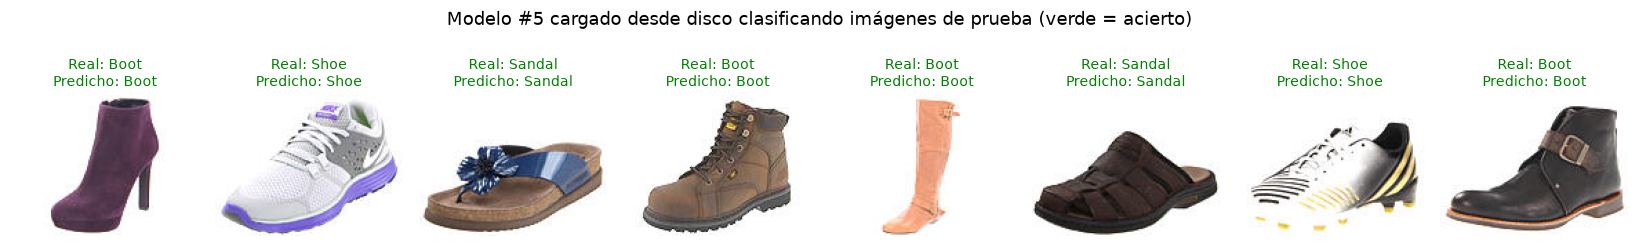

In [ ]:
# =====================================================================================
# QUÉ HACE: carga el modelo #5 (recomendado en la sección 7.3) desde el disco y clasifica
# 8 imágenes de prueba leyendo directamente sus archivos .jpg.
# =====================================================================================

def preparar_imagen(ruta):
    # Repite exactamente el preprocesamiento del entrenamiento: gris, 32x32, [0, 1], vector de 1 024.
    # El modelo hace el resto (escalado y PCA) porque están dentro del pipeline.
    imagen = Image.open(ruta).convert("L").resize((IMG_SIZE, IMG_SIZE))
    return np.asarray(imagen, dtype=np.float32).ravel() / 255.0

modelo = joblib.load(f"modelos/{PREFIJO}_svm_cfg5_poly.joblib")
# Misma partición que en la sección 4.1 (misma semilla y estratificación) -> mismas imágenes de prueba
_, rutas_test = train_test_split(np.array(rutas), test_size=TEST_SIZE, stratify=y, random_state=SEED)
muestra = np.random.default_rng(SEED).choice(rutas_test, 8, replace=False)

fig, axes = plt.subplots(1, 8, figsize=(15, 2.6))
for ax, ruta in zip(axes, muestra):
    real = os.path.basename(os.path.dirname(ruta))                 # la carpeta indica la clase real
    pred = modelo.predict(preparar_imagen(ruta)[None, :])[0]      # [None, :] -> matriz de 1 fila
    ax.imshow(Image.open(ruta).convert("RGB")); ax.axis("off")
    ax.set_title(f"Real: {real}\nPredicho: {pred}", fontsize=9, color="green" if pred == real else "red")
plt.suptitle("Modelo #5 cargado desde disco clasificando imágenes de prueba (verde = acierto)")
plt.tight_layout(); plt.savefig("figuras/uso_modelo_predicciones.png"); plt.show()

## 11. Declaración de uso de herramientas de inteligencia artificial

* **Herramienta utilizada:** Claude (Anthropic), asistente de lenguaje.
* **Rol de la herramienta:** apoyo en la estructuración del notebook, la redacción del código de carga, del pipeline y de las visualizaciones, basandose en el skill proporcionado.
* **Decisiones y trabajo del grupo:** *revisión y validación del código, ejecución de cada configuración y toma de capturas, verificación de las cifras, aprobación del preprocesamiento (escala de grises, 32 × 32, PCA del 80 %), selección del modelo #5 como recomendado, redacción final del informe, etc.*

### Archivos generados

| Archivo | Contenido |
|---|---|
| `silva_leon_tobar_gomez_svm.ipynb` | Este notebook, con todas las salidas |
| `modelos/silva_leon_tobar_gomez_svm_cfg{1..5}_*.joblib` | Los cinco pipelines entrenados (escalado + PCA + SVM) |
| `modelos/silva_leon_tobar_gomez_svm_metadatos.json` | Versiones de librerías, preprocesamiento y métricas de cada modelo |
| `silva_leon_tobar_gomez_tabla_experimentos_svm.csv` | Tabla 1 en formato CSV |
| `figuras/*.png` | EDA, varianza PCA, 5 matrices de confusión, comparación de configuraciones, fronteras 2D y predicciones, para el informe |

### Descarga de resultados (solo en Google Colab)

En Colab, los archivos que crea el notebook se guardan en el disco temporal de la máquina virtual (`/content`) y se borran al cerrar la sesión. La siguiente celda los empaqueta en un `.zip` y lo descarga al computador. En un equipo local no hace nada, porque los archivos ya quedan en la carpeta del notebook.

In [24]:
# =====================================================================================
# QUÉ HACE: en Colab, comprime modelos, figuras y tabla en un .zip y lo descarga.
# =====================================================================================
if EN_COLAB:
    import shutil
    from google.colab import files
    os.makedirs("entregables", exist_ok=True)
    for carpeta in ("modelos", "figuras"):
        shutil.copytree(carpeta, os.path.join("entregables", carpeta), dirs_exist_ok=True)
    shutil.copy(f"{PREFIJO}_tabla_experimentos_svm.csv", "entregables")
    zip_path = shutil.make_archive(f"{PREFIJO}_svm_resultados", "zip", "entregables")
    files.download(zip_path)
    print("Descargando:", zip_path)
else:
    print("Ejecución local: los resultados ya están en", os.path.abspath("."))

Ejecución local: los resultados ya están en /home/ur92/Documentos/InteligenciaComputacional/taller2_svm
